# Predikcia Pulzaru (rýchlo rotujúcej neutrónovej hviezdy)
Vypracovala: Simona Bednáriková
Dátum: 27.11.2026

## Kontext
Pulsary sú vzácnym typom neutrónových hviezd, ktoré vyžarujú rádiové vlny, ktoré dokážeme zachytiť aj tu na Zemi. Vznikajú po výbuchu supernovy.

Sú pre vedeckú komunitu nástrojom na skúmanie vesmíru. Potrebujeme ich vedieť identifikovať napr. na:
- pochopenie extrémnej hmoty: na Zemi nedokážeme stlačiť hmotu tak silno ako v pulzare. Sledovaním pulzarov zisťujeme, ako sa v takých extrémoch správajú atómy a magnetizmus.
- meranie vesmíru či gravitačných vĺn: tzv. milisekundové pulzary blikajú rovnako presne ako atómové hodinky, stačí sledovať, či ich signál k nám mešká alebo ide skôr. Z toho vieme zistiť, či cez vesmír prešla gravitačná vlna alebo či je medzi nami a pulzarom nejaký neviditeľný objekt (napr. čierna diera).

##Ako ich vieme na oblohe identifikovať? High Time Resolution Universe (HTRU)
Toto meranie zachytáva rýchle rádiové záblesky a pravidelné pulzy z vesmíru (milisekundové pulzary a jednorazové záblesky zvané Fast Radio Bursts).

Vykonáva sa pomocou systematického skenovanie celej oblohy pomocou rádioteleskopov. Parkes v Austrálii (južná obloha) a Effelsberg v Nemecku (severná obloha). Tieto teleskopy zachytávajú:
- rádiové vlny (nie svetlo): zachytávajú rádiový šum z vesmíru na frekvencii okolo 1,4 GHz (podobné pásmo, aké používajú napr. satelity alebo Wi-Fi).
- extrémne krátke zmeny: Prístroje merajú silu rádiového signálu každých 54 až 64 mikrosekúnd (cca 15 000/s). Vďaka tomu zachytia aj záblesk, ktorý trvá len zlomok milisekundy.
- Rozdelenie na stovky „farieb“: Zachytávaný rádiový signál nie je jeden celok – digitálny prijímač ho rozseká na stovky úzkych frekvenčných kanálov

##Cieľ projektu - binárna klasifikácia

Rádioteleskopy pri hľadaní pulzarov zachytia obrovské množstvo kandidátov, no takmer všetky sú len rušenie (mobilné siete, satelity, šum prístrojov). Skutočných pulzarov je málo. Naším cieľom binárna klasifikácia a teda naučiť model  **rozhodnúť, či je kandidát skutočný pulzar (1) alebo šum (0)**.

###Čiastkové ciele
1. Porovnať 3 klasifikačné modely: (logistická regresia, K-najbližších susedov (KNN), Náhodný les (Random Forest)) s vyladenými hyperparametrami a vybrať najvhodnejší.
2. Overiť, či sú rozdiely medzi modelmi skutočné, alebo len náhodné, pomocou opakovanej krížovej validácie.
3. Nájsť vhodný rozhodovací prah: koľko kandidátov musí astronóm ručne skontrolovať, ak chce nájsť 90 %, 95 % alebo 99 % pulzarov.

*Bonus: učenie bez učiteľa. Zistiť, či by metóda K-means našla pulzary aj bez značiek, iba podľa podobnosti kandidátov, a porovnať ju s modelmi s učiteľom.*

## Dáta
Dáta sú verejné a sťahujeme ich priamo z Kaggle: https://www.kaggle.com/datasets/charitarth/pulsar-dataset-htru2

Jedná sa o kandidátov na pulsary. Dáta boli zhromaždené v rámci prieskumu High Time Resolution Universe (HTRU).

### Informácie o atribútoch
Každý kandidát je opísaný 8 spojitými premennými a jednou cieľovou premennou (0/1).
Prvé štyri premenné sú štatistiky integrovaného pulzného profilu, ďalšie štyri sú tie isté štatistiky DM-SNR krivky.

Integrovaný pulzný profil - každý pulzar vysiela pulzy v typickom vzore, tzv. pulznom profile. Je to akoby jeho odtlačok prsta, podľa ktorého sa dá pulzar rozpoznať. Profil sa však pri každej otáčke trochu líši, signál nie je rovnomerný ani stabilný v čase, a preto je ťažké pulzar zachytiť. Stabilný tvar získame až vtedy, keď profil spriemerujeme cez tisíce otáčok. Skutočný pulzar má úzky a ostrý pulz, šum je plochý.

DM-SNR krivka. Rádiové vlny z pulzaru putujú na Zem cez vesmír, ktorý je plný voľných elektrónov. Pri interakcii s nimi sa vlny spomaľujú, a to tým viac, čím majú nižšiu frekvenciu. Pulzar vysiela na širokom rozsahu frekvencií, takže nižšie frekvencie dorazia k teleskopu neskôr ako vyššie. Tento jav sa nazýva disperzia a jej mieru udáva DM (dispersion measure). DM-SNR krivka ukazuje, aký silný je signál (SNR, pomer signálu a šumu) pri rôznych hodnotách DM. Signál zo skutočného pulzaru je najsilnejší pri DM > 0, kým pozemské rušenie, ktoré cez vesmír necestovalo, je najsilnejšie pri DM ≈ 0.

*Opisy kriviek voľne prebraté z originálneho opisu uvedenom pri dátovom súbore podľa [Utsav Murarka: Pulsar-identification]

| # | Premenná v datasete | Opis | Rozsah (min – max) | Bežné hodnoty (5. – 95. percentil) | Medián šum / pulzar |
|---|---|---|---|---|---|
| 1 | `mean_profile` | stredná hodnota integrovaného profilu | 5,8 – 192,6 | 57 – 143 | 117,3 / 54,3 |
| 2 | `std_profile` | smerodajná odchýlka integrovaného profilu | 24,8 – 98,8 | 35 – 56 | 47,5 / 37,3 |
| 3 | `kurtosis_profile` | nadmerná špicatosť integrovaného profilu, teda aký ostrý je pulz | −1,9 – 8,1 | −0,2 – 2,7 | 0,2 / 3,0 |
| 4 | `skewness_profile` | šikmosť integrovaného profilu, teda nakoľko je pulz nesymetrický | −1,8 – 68,1 | −0,6 – 10,1 | 0,1 / 11,6 |
| 5 | `mean_dmsnr` | stredná hodnota DM-SNR krivky | 0,2 – 223,4 | 1,0 – 83,0 | 2,6 / 33,5 |
| 6 | `std_dmsnr` | smerodajná odchýlka DM-SNR krivky | 7,4 – 110,6 | 11 – 75 | 17,6 / 59,4 |
| 7 | `kurtosis_dmsnr` | nadmerná špicatosť DM-SNR krivky | −3,1 – 34,5 | 0,5 – 15,8 | 8,8 / 1,9 |
| 8 | `skewness_dmsnr` | šikmosť DM-SNR krivky | −2,0 – 1 191,0 | −0,5 – 296,4 | 90,7 / 2,6 |
| 9 | `target_pulsar` | **cieľová premenná**: 1 = pulzar, 0 = šum | 0 / 1 | – | – |

### Súhrn datasetu
| | Počet | Podiel |
|---|---|---|
| Všetky pozorovania | 17 898 | 100 % |
| Pulzary (1) | 1 639 | 9,2 % |
| Šum (0) | 16 259 | 90,8 % |

Premenné majú **veľmi rozdielne mierky** (napr. `kurtosis_profile` do 8, `skewness_dmsnr` až do 1 191). Preto ich pred modelmi založenými na vzdialenostiach budeme škálovať.

Čo je pulsar - video: https://youtu.be/gjLk_72V9Bw?si=Co4abs6ldhKkJtZQ


In [2]:
# knižnice na prácu s dátami a grafy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# rozdelenie dát, krížová validácia a ladenie hyperparametrov
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV,
                                     RepeatedStratifiedKFold)
# príprava dát (škálovanie, transformácia)
from sklearn.preprocessing import StandardScaler, PowerTransformer
# modely
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
# metriky a grafy na vyhodnotenie modelov
from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             classification_report,
                             ConfusionMatrixDisplay,
                             RocCurveDisplay,
                             precision_recall_curve,
                             PrecisionRecallDisplay,
                             silhouette_score)
# sťahovanie dát z Kaggle
import kagglehub
import os

# 1. Exploratívna analýza dát
## 1.1 Načítanie dát z Kaggle

In [3]:
# stiahneme dataset z Kaggle a vypíšeme, aké súbory obsahuje
path = kagglehub.dataset_download("charitarth/pulsar-dataset-htru2")
print(os.listdir(path))

# súbor nemá hlavičku, preto stĺpce pomenujeme sami (poradie podľa popisu datasetu)
columns = ["mean_profile", "std_profile", "kurtosis_profile",
           "skewness_profile", "mean_dmsnr", "std_dmsnr",
           "kurtosis_dmsnr", "skewness_dmsnr", "target_pulsar"]

df = pd.read_csv(f"{path}/HTRU_2.csv", header=None, names=columns)

print("#riadkov, #stĺpcov:",df.shape)
print("Názvy stĺpcov:", df.columns)
df.head()

100%|██████████| 768k/768k [00:00<00:00, 16.4MB/s]

Extracting files...
['HTRU_2.csv']


#riadkov, #stĺpcov: (17898, 9)
Názvy stĺpcov: Index(['mean_profile', 'std_profile', 'kurtosis_profile', 'skewness_profile',
       'mean_dmsnr', 'std_dmsnr', 'kurtosis_dmsnr', 'skewness_dmsnr',
       'target_pulsar'],
      dtype='object')


,mean_profile,std_profile,kurtosis_profile,skewness_profile,mean_dmsnr,std_dmsnr,kurtosis_dmsnr,skewness_dmsnr,target_pulsar
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0


In [4]:
# počet riadkov, dátové typy a počet vyplnených hodnôt v každom stĺpci
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17898 entries, 0 to 17897
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   mean_profile      17898 non-null  float64
 1   std_profile       17898 non-null  float64
 2   kurtosis_profile  17898 non-null  float64
 3   skewness_profile  17898 non-null  float64
 4   mean_dmsnr        17898 non-null  float64
 5   std_dmsnr         17898 non-null  float64
 6   kurtosis_dmsnr    17898 non-null  float64
 7   skewness_dmsnr    17898 non-null  float64
 8   target_pulsar     17898 non-null  int64  
dtypes: float64(8), int64(1)
memory usage: 1.2 MB


Dataset má 17 898 pozorovaní, indexy od 0 po 17 897, 9 stĺpcov, z toho 8 vysvetľujúcich a 1 cieľová premenná.

- Nemáme žiadne chýbajúce hodnoty (17898 = #riadkov). Nie je teda potrebné žiadne riadky mazať či nahrádzať chýbajúce hodnoty.
- Všetkých 8 vysvetľujúcich premenných je dátového typu float64, čiže spojité desatinné čísla,
- `target_pulsar` má dátový typ int64, je to naša cieľová premenná  - celé číslo 0/1.
- Žiadny stĺpec nie je textový, takže netreba kódovanie kategórií (one-hot a pod.).
- Nemáme kategoriálne premenné.
- Dataset má 1,2 MB - je teda malý a modely by sa mali dať natrénovať veľmi rýchlo.


In [5]:
# počet chýbajúcich hodnôt v každom stĺpci a počet duplicitných riadkov
print("Chýbajúce hodnoty:", df.isna().sum())
print("Duplicitné riadky:", df.duplicated().sum())

Chýbajúce hodnoty: mean_profile        0
std_profile         0
kurtosis_profile    0
skewness_profile    0
mean_dmsnr          0
std_dmsnr           0
kurtosis_dmsnr      0
skewness_dmsnr      0
target_pulsar       0
dtype: int64
Duplicitné riadky: 0


Dáta neobsahujú chýbajúce hodnoty ani duplicity.

## 1.2 Deskriptívna štatistika

In [6]:
# opisné štatistiky; .Transponované, zaokrúhlené na 2 desatinné miesta
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
mean_profile,17898.0,111.08,25.65,5.81,100.93,115.08,127.09,192.62
std_profile,17898.0,46.55,6.84,24.77,42.38,46.95,51.02,98.78
kurtosis_profile,17898.0,0.48,1.06,-1.88,0.03,0.22,0.47,8.07
skewness_profile,17898.0,1.77,6.17,-1.79,-0.19,0.20,0.93,68.10
mean_dmsnr,17898.0,12.61,29.47,0.21,1.92,2.80,5.46,223.39
std_dmsnr,17898.0,26.33,19.47,7.37,14.44,18.46,28.43,110.64
kurtosis_dmsnr,17898.0,8.30,4.51,-3.14,5.78,8.43,10.70,34.54
skewness_dmsnr,17898.0,104.86,106.51,-1.98,34.96,83.06,139.31,1191.00
target_pulsar,17898.0,0.09,0.29,0.00,0.00,0.00,0.00,1.00


### Interpretácia deskriptívnych štatistík


1. Premenné majú veľmi rozdielne mierky - `kurtosis_profile` má hodnoty od −1.88 do 8.07,`skewness_dmsnr`má hodnoty od −1.98 do 1 191. Preto budeme musieť dataset preškálovať.
2. Niektoré premenné sú silne zošikmené doprava (priemer je výrazne nad mediánom a maximum leží ďaleko za 75. percentilom). V ďalších krokoch preto preskúmame odľahlé hodnoty.
3. Nevyvážené tredy: priemer premennej `target_pulsar` je 0,09, teda iba približne 9 % kandidátov sú pulzary - toto je v súlade s opisom datasetu na Kaggle.

**Pozorovania pri jednotlivých premenných**
* `mean_profile`: priemer (111,1) je ako jediný **nižší** ako medián (115,1), čiže rozdelenie má dlhší **ľavý** chvost. Minimum je 5,8, hoci 75 % hodnôt je nad 100. Nízke hodnoty pravdepodobne patria pulzarom.
* `std_profile`: **najstabilnejšia premenná**. Priemer a medián sú takmer zhodné (46,6 a 47,0) a polovica hodnôt leží v úzkom pásme 42 – 51.
* `kurtosis_profile`: polovica hodnôt leží medzi 0,03 a 0,47, no maximum je 8,07, teda **17-krát viac ako Q3**. Vysoká špicatosť znamená ostrý pulz, čo je typický znak pulzaru.
* `skewness_profile`: smerodajná odchýlka (6,17) je **3,5-krát väčšia ako priemer** (1,77). Je to spôsobené niekoľkými extrémnymi hodnotami až do 68.
* `mean_dmsnr`: **najviac zošikmená premenná**. Polovica kandidátov má hodnotu pod 2,8, no maximum je 223,4, čo je **viac ako 40-násobok Q3** (5,46).
* `std_dmsnr`: hodnoty nikdy neklesnú pod 7,4. Priemer (26,3) je o 40 % vyšší ako medián (18,5), takže menšia skupina kandidátov má výrazne rozkolísanejšiu DM-SNR krivku.
* `kurtosis_dmsnr`: jediná premenná z DM-SNR krivky, ktorá je **približne symetrická** (priemer 8,30, medián 8,43). Zároveň má **najnižšie minimum** zo všetkých premenných (−3,14).
* `skewness_dmsnr`: má **najväčší rozsah** zo všetkých premenných (od −2 do 1 191) a smerodajná odchýlka (106,5) je dokonca **väčšia ako priemer** (104,9).

## 1.3 Závislá premenná

---



target_pulsar
0    16259
1     1639
Name: count, dtype: int64


/tmp/ipykernel_1422/3388170175.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set(title="Počet kandidátov podľa triedy", xlabel="Cieľová_premenná", ylabel="Počet", xticklabels=["Šum", "Pulzar"])


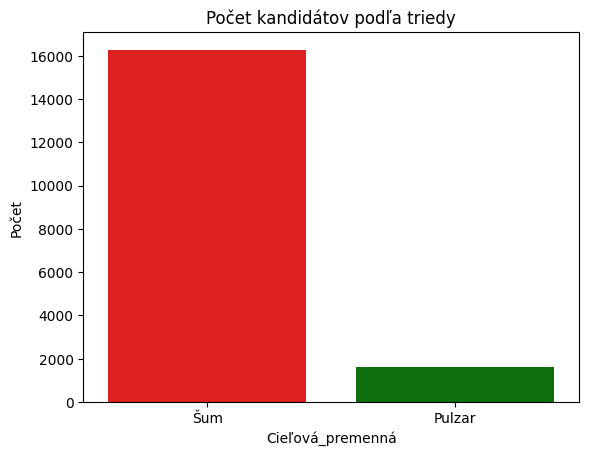

In [10]:
# počet kandidátov v každej triede
print(df["target_pulsar"].value_counts())


ax = sns.countplot(data=df, x="target_pulsar", hue="target_pulsar", palette=["red", "green"], legend=False) #stĺpcový graf počtu kandidátov, každá trieda vlastnou farbou

# nadpis, popisy osí a názvy tried namiesto 0/1
ax.set(title="Počet kandidátov podľa triedy", xlabel="Cieľová_premenná", ylabel="Počet", xticklabels=["Šum", "Pulzar"])
plt.show()


Triedy sú výrazne nevyvážené, 16 259 kandidátov je šum a len 1 639 (9,2 %) sú pulzary.
Na základe týchto zistení
1. budeme dáta deliť stratifikovane (rovnaké percentuálne zastúpenie pulzarov trénovacej aj testovacej sade),
2. modely nebudeme hodnotiť cez accuracy, ktorá by bola v tomto prípade skreslená ale cez recall, precision a ich harmonický priemer, F1 skóre,
3. použijeme parameter`class_weight="balanced"`,pretože dáva väčšiu váhu chybám na menšinovej triede (t.j. viac trestá chyby na menšinovej triede).

## 1.4 Rozdelenia premenných podľa cieľovej premennej (koeficient prekrytia (overlapping coefficient, OVL))
Pre každú premennú porovnáme, ako vyzerá jej rozdelenie pri šume a pri pulzaroch pomocou prekrývajúcich sa histogramov. Čím menej sa krivky prekrývajú, tým lepšie premenná triedy oddeľuje. Všetky majú plochu pod krivkou 1.

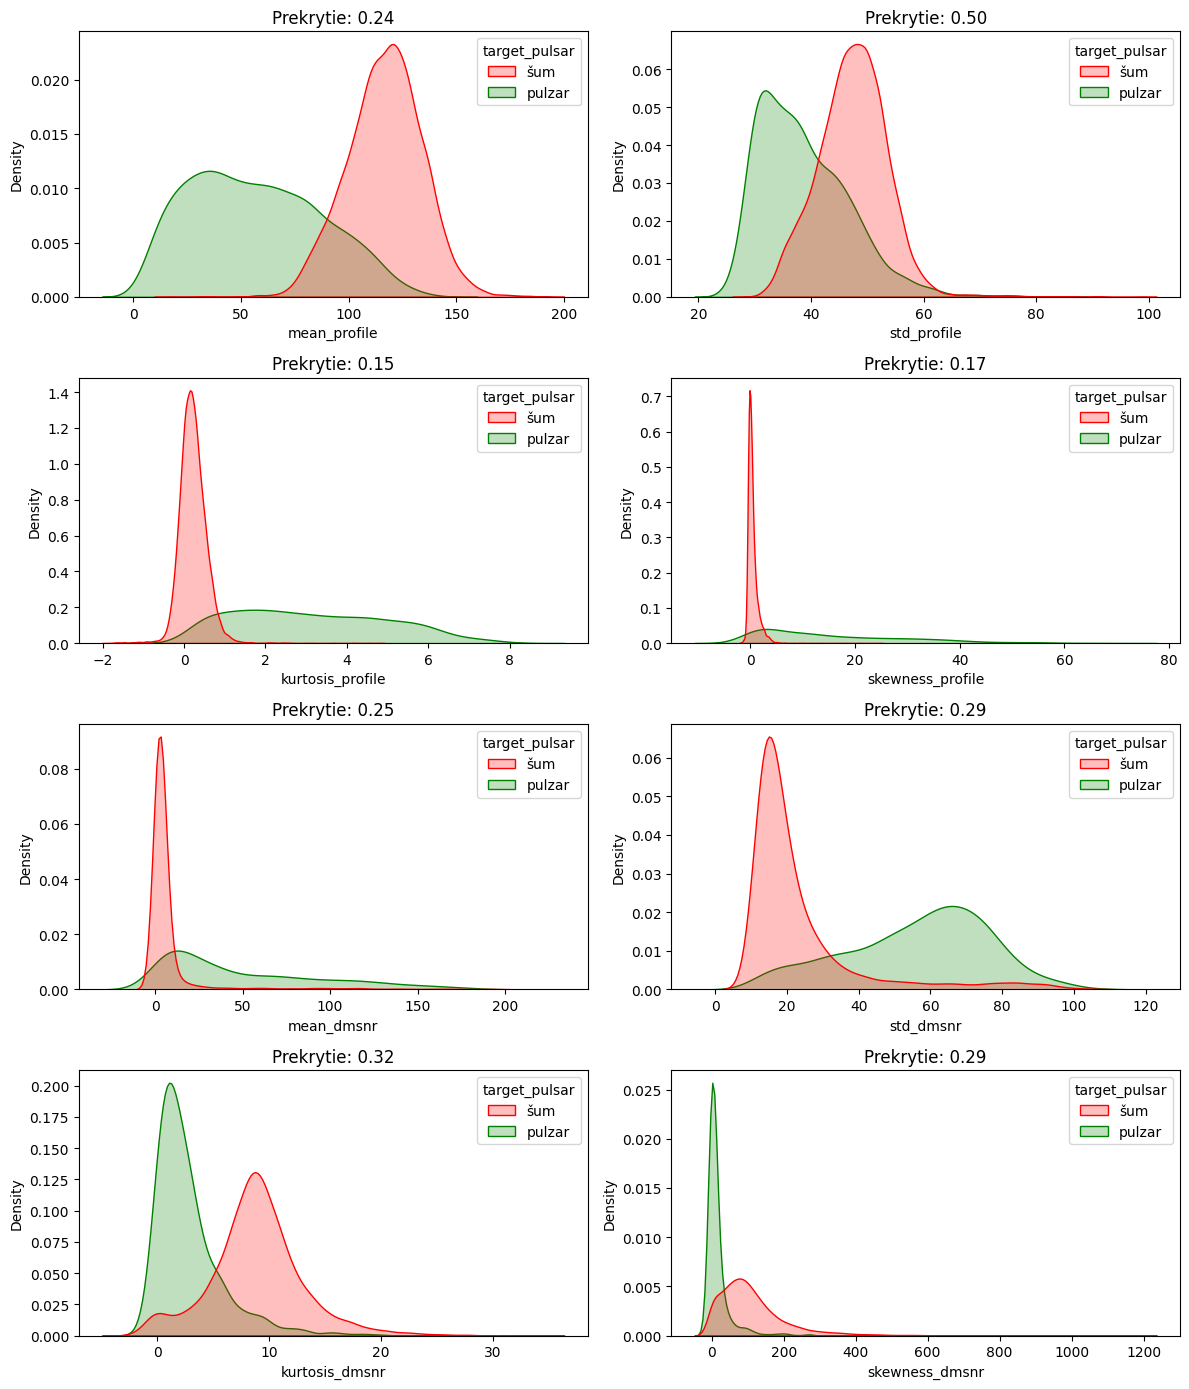

,prekrytie
kurtosis_profile,0.15
skewness_profile,0.17
mean_profile,0.24
mean_dmsnr,0.25
skewness_dmsnr,0.29
std_dmsnr,0.29
kurtosis_dmsnr,0.32
std_profile,0.50


In [17]:

from scipy.stats import gaussian_kde
import numpy as np

# zoznam vysvetľujúcich premenných (všetky stĺpce okrem cieľovej premennej)
features = df.columns.drop("target_pulsar")

# mriežka 4x2 grafov, pre každú premennú jeden
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

overlap = {}
for ax, col in zip(axes.flat, features):
    # hustota hodnôt zvlášť pre šum a pre pulzary;
    # common_norm=False: každá krivka má plochu 1, aby sa dali porovnať aj pri malom počte pulzarov
    sns.kdeplot(data=df.replace({"target_pulsar": {0: "šum", 1: "pulzar"}}),
                x=col,
                hue="target_pulsar",  # samostatná krivka pre šum a pre pulzary
                common_norm=False,  #plocha 1 - porovnatelnosť
                fill=True,
                ax=ax,
                palette={"šum": "red", "pulzar": "green"})

    # plocha prekrytia oboch kriviek (0 = triedy úplne oddelené, 1 = totožné krivky)
    x = np.linspace(df[col].min(), df[col].max(), 1000)              # 1000 bodov na osi x

    noise = gaussian_kde(df.loc[df["target_pulsar"] == 0, col])(x)   # krivka šumu - estimates the probability density function (PDF)
    pulsar = gaussian_kde(df.loc[df["target_pulsar"] == 1, col])(x)  # krivka pulzarov

    overlap[col] = (np.minimum(noise, pulsar) * (x[1] - x[0])).sum() # plocha pod menšou z kriviek

    ax.set_title(f"Prekrytie: {overlap[col]:.2f}")

plt.tight_layout()   # upraví medzery, aby sa popisy neprekrývali
plt.show()

# premenné zoradené od tej, ktorá triedy oddeľuje najlepšie
pd.Series(overlap, name="prekrytie").sort_values().round(2).to_frame()

* **Najlepšie oddeľujú triedy premenné integrovaného profilu.** Šum má `kurtosis_profile` sústredenú okolo 0, kým pulzary majú hodnoty 1 až 8. Integral prekrytia je taktiež najmenší, 0,15 . Pulzar má totiž úzky, ostrý pulz (špicaté rozdelenie), kým šum je plochý. Podobne pulzary majú výrazne nižší `mean_profile`.
* Pri **DM-SNR krivke** majú pulzary vyšší `mean_dmsnr` a `std_dmsnr`. Skutočný pulzar má silný signál pri konkrétnej hodnote rozptylu (DM > 0), kým pozemské rušenie je najsilnejšie pri DM ≈ 0.
* `skewness_profile` vyzerá takmer ako `kurtosis_profile` a `skewness_dmsnr` ako `kurtosis_dmsnr`. Tieto dvojice sú pravdepodobne silno závislé (multikolinearita),overíme to v korelačnej analýze – pre lineárne modely potom z každej dvojice ponecháme len jednu premennú.

## 1.5 Odľahlé pozorovania
Odľahlé hodnoty hľadáme metódou IQR: hodnota je odľahlá, ak leží mimo intervalu
[Q1 − 1,5·IQR ; Q3 + 1,5·IQR], kde IQR = Q3 − Q1 (Q1, Q3 sú 25. a 75. percentil). Zároveň zistíme, koľko percent odľahlých hodnôt patrí pulzarom.

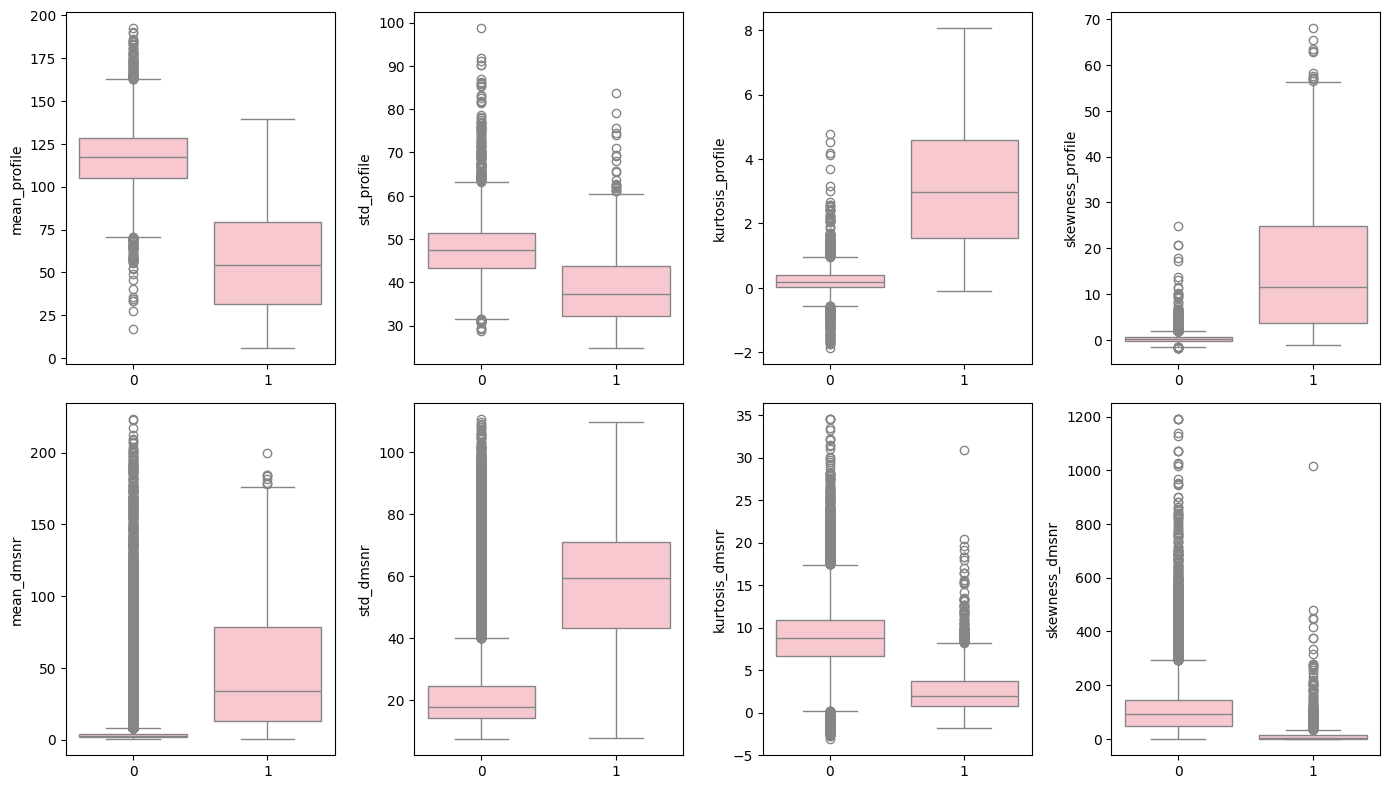

In [18]:
# boxploty každej premennej zvlášť pre šum (0) a pulzary (1)
fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x="target_pulsar", y=col, ax=ax, color = "pink")
    ax.set(xlabel="", ylabel=col)
plt.tight_layout()
plt.show()

Boxploty počítajú kvartily zvlášť pre každú triedu. Šum má hodnoty sústredené v úzkom pásme, preto má veľa „krúžkov“ (odľahlých hodnôt v rámci svojej triedy). Pulzary sú rozptýlené viac, ich fúzy siahajú ďaleko a odľahlých hodnôt majú málo.

Krúžky pri triede 0 sú zaujímavé: ide o šumové signály, ktorých hodnoty spadajú do rozsahu typického pre pulzary (napr. `mean_profile` pod 70 alebo `kurtosis_profile` nad 1). Sú to ťažké prípady, ktoré pravdepodobne spôsobia falošné poplachy modelu.

Tabuľka nižšie naopak počíta hranice IQR z celého datasetu. Keďže 91 % dát tvorí šum, hranice sú nastavené podľa šumu a typické pulzary za nimi ležia. Preto väčšinu odľahlých hodnôt tvoria pulzary.

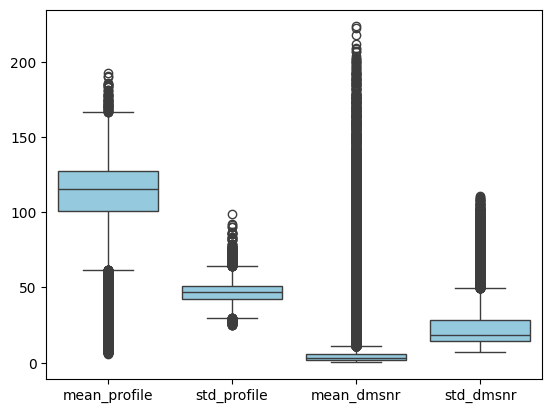

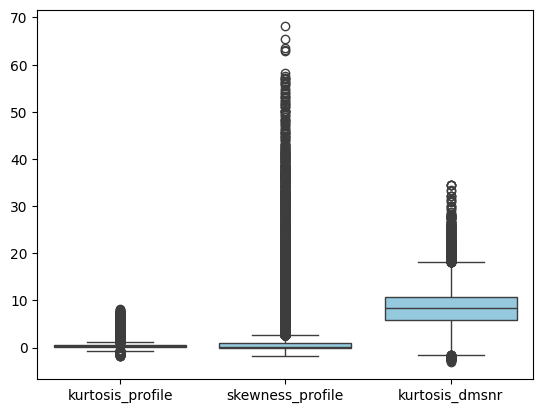

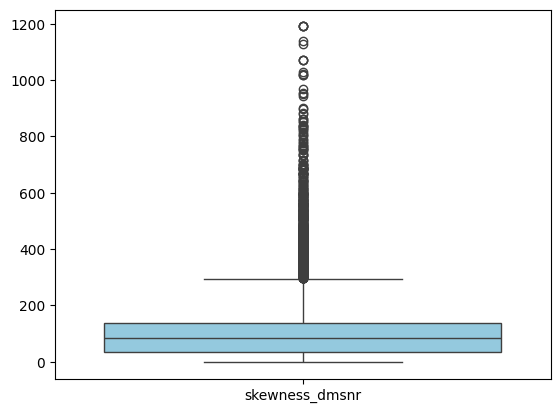

In [19]:
# boxploty za celý dataset, premenné s podobným rozsahom hodnôt v spoločnom grafe
# premenné s hodnotami do ~220
sns.boxplot(data=df[["mean_profile", "std_profile", "mean_dmsnr", "std_dmsnr"]], color="skyblue")
plt.show()

# premenné s hodnotami do ~70
sns.boxplot(data=df[["kurtosis_profile", "skewness_profile", "kurtosis_dmsnr"]], color="skyblue")
plt.show()

# skewness_dmsnr má hodnoty až do ~1 200, preto samostatne
sns.boxplot(data=df[["skewness_dmsnr"]], color="skyblue")
plt.show()

In [20]:
# kvartily a medzikvartilové rozpätie (IQR) každej premennej
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
# True tam, kde hodnota leží mimo intervalu [Q1 - 1,5*IQR ; Q3 + 1,5*IQR]
is_outlier = ((df[features] < q1 - 1.5 * iqr) |
              (df[features] > q3 + 1.5 * iqr))
# počet odľahlých hodnôt, ktoré patria pulzarom
outlier_pulsars = is_outlier[df["target_pulsar"] == 1].sum()

pd.DataFrame({
    "odľahlé": is_outlier.sum(),
    "z toho pulzary [%]": (100 * outlier_pulsars / is_outlier.sum()).round(1),
})

,odľahlé,z toho pulzary [%]
mean_profile,1030,92.0
std_profile,262,52.3
kurtosis_profile,1596,85.0
skewness_profile,1901,69.0
mean_dmsnr,2927,43.8
std_dmsnr,2346,46.9
kurtosis_dmsnr,487,1.6
skewness_dmsnr,901,1.0


Odľahlých hodnôt je veľa (napr. 2 927 pri `mean_dmsnr`), no pri premenných integrovaného profilu patrí 70-92 % z nich pulzarom, napriek tomu, že pulzary tvoria 9 % dát. Odľahlé hodnoty teda nie sú chyby merania, ale signál, ktorý hľadáme. Ak by sme ich odstránili, vyhodili by sme veľkú časť pulzarov, preto ich v dátach ponechávame.

## 1.6 Korelácie

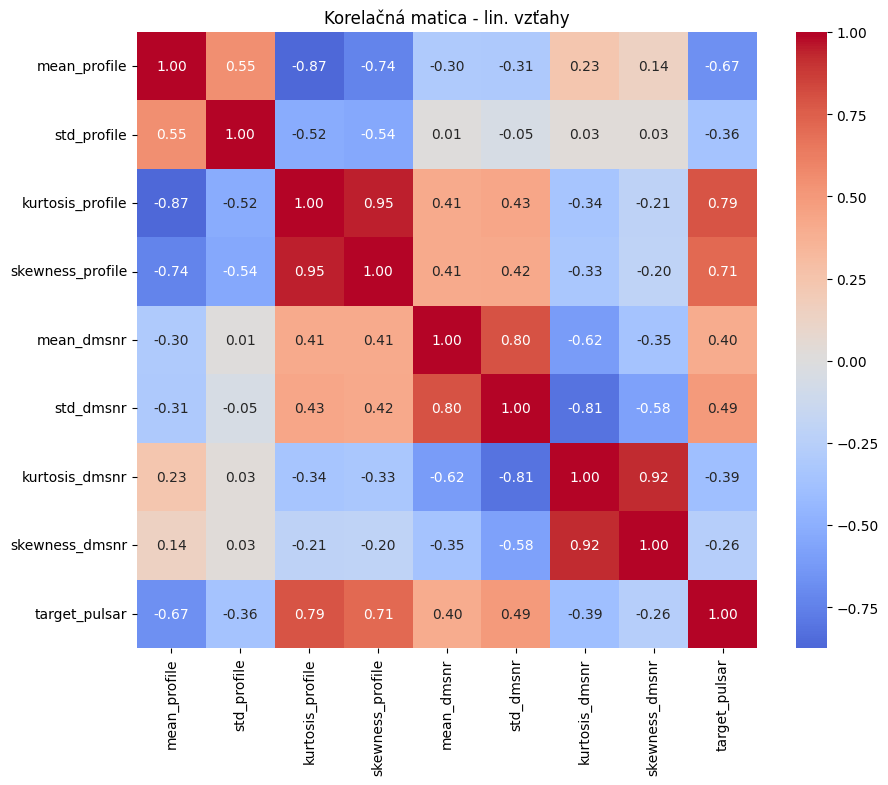

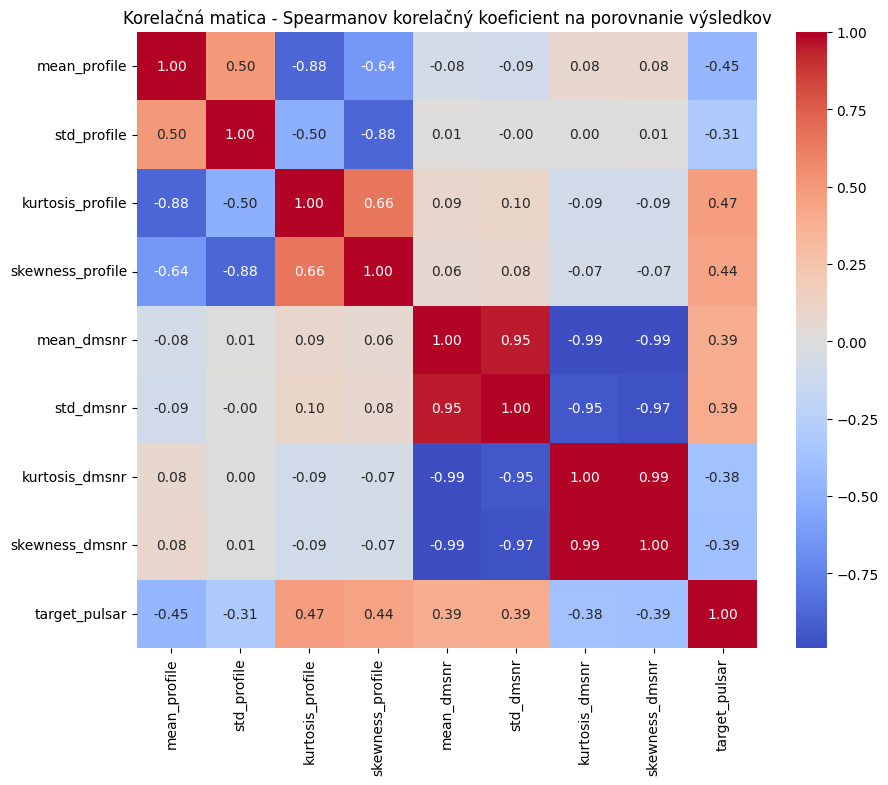

In [27]:
# korelačná matica všetkých premenných
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelačná matica - lin. vzťahy")
plt.show()

# korelačná matica všetkých premenných
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelačná matica - Spearmanov korelačný koeficient na porovnanie výsledkov")
plt.show()

* `kurtosis_profile` a `skewness_profile` (r = 0,95), `kurtosis_dmsnr` a `skewness_dmsnr` (r = 0,92). Jednu premennú z každej z týchto dvojíc teda vyhodíme, nebude mať žiadnu pridanú hodnotu.
* S cieľovou premennou najsilnejšie koreluje `kurtosis_profile` (r = 0,79) a `mean_profile` (r = −0,67), čo zodpovedá grafom vyššie.

Korelačná matica, kt. používa Pearsonov koeficient meria iba lineárny vzťah. Pri zošikmených premenných s odľahlými hodnotami môže silný nelineárny vzťah podhodnotiť. To pozorujeme v rozdielnych výsledkoch, ktoré pozorujeme v druhom grafe.
Spearmanov koeficient zachytil aj nelineárne monotónne vzťahy napr. `mean_dmsnr` – `kurtosis_dmsnr` dáva −0,99 vs. −0,62. Premenné DM-SNR krivky sú teda navzájom závislejšie, než ukazuje Pearsonova matica.

# 2. Príprava dát a rozdelenie na trénovaciu a testovaciu časť
## 2.1 Rozdelenie dát
Dáta rozdelíme v pomere **80 : 20**. Parameter `stratify=y` zaručí, že v oboch častiach bude rovnaký podiel
pulzarov (pri nevyvážených triedach je to dôležité). Rozdelenie robíme **pred** výberom premenných a škálovaním,
aby sa žiadna informácia z testovacích dát nedostala do trénovania.

In [28]:
# X = vysvetľujúce premenné, y = cieľová premenná
X = df[features]
y = df["target_pulsar"]

# 80 % trénovacie, 20 % testovacie dáta; stratify=y zachová podiel pulzarov v oboch častiach
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Trénovacie:", X_train.shape, "| Testovacie:", X_test.shape)
print("Podiel pulzarov v train:", round(y_train.mean(), 3))
print("Podiel pulzarov v test: ", round(y_test.mean(), 3))

Trénovacie: (14318, 8) | Testovacie: (3580, 8)
Podiel pulzarov v train: 0.092
Podiel pulzarov v test:  0.092


## 2.2 Výber premenných: odstránenie nadbytočných
Z korelačnej matice vidno dvojice premenných, ktoré nesú takmer rovnakú informáciu. Vyhľadáme všetky dvojice
s |r| > 0,9 a z každej ponecháme tú, ktorá **silnejšie koreluje s cieľovou premennou**.

In [30]:
# korelácie medzi premennými a absolútna korelácia každej premennej s cieľovou premennou
corr = X_train.corr(method= "pearson")
target_corr = X_train.corrwith(y_train).abs()

# prejdeme všetky dvojice premenných a vypíšeme tie s |r| > 0,9
for i, a in enumerate(features):
    for b in features[i + 1:]:
        if abs(corr.loc[a, b]) > 0.9:
            print(f"{a} vs {b}: r = {corr.loc[a, b]:.2f}")
            print(f"   korelácia s cieľom: {target_corr[a]:.2f}",
                  f"vs {target_corr[b]:.2f}")

kurtosis_profile vs skewness_profile: r = 0.95
   korelácia s cieľom: 0.79 vs 0.71
kurtosis_dmsnr vs skewness_dmsnr: r = 0.92
   korelácia s cieľom: 0.39 vs 0.26


Z každej dvojice vyhadzujeme šikmosť (skewness), lebo slabšie koreluje s cieľovou premennou ako špicatosť (kurtosis).

In [31]:
# z každej silno korelovanej dvojice odstránime premennú, ktorá slabšie koreluje s cieľom
to_drop = ["skewness_profile", "skewness_dmsnr"]
X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)
list(X_train.columns)

['mean_profile',
 'std_profile',
 'kurtosis_profile',
 'mean_dmsnr',
 'std_dmsnr',
 'kurtosis_dmsnr']

## 2.3 Škálovanie a transformácia
* Škálovanie potrebujú modely, ktoré pracujú so vzdialenosťami alebo váhami: logistická regresia a KNN. Bez neho by `std_dmsnr` (hodnoty do ~110) prevalcovala `kurtosis_profile` (hodnoty ~0 až 8).
* Premenné sú silne zošikmené- použijeme Yeo-Johnsonovu transformáciu (nelin. transformácia). Robí to isté ako logaritmus (stiahne dlhý chvost zošikmenej premennej a priblíži rozdelenie normálnemu). Logaritmus pri našich dátach použiť nemôžeme, lebo `kurtosis_profile` a `kurtosis_dmsnr` majú aj záporné hodnoty a logaritmus záporného čísla neexistuje. Yeo-Johnsonova transformácia funguje aj so zápornými číslami.
* Použijeme ju cez `PowerTransformer`, ktorý dáta štandardizuje (priemer=0, smerodajná odchýlka=1) => nahrádza `StandardScaler`.
* Transformáciu robíme iba na trénovacích dátach (`fit_transform`) a na testovacie ju aplikujeme (`transform`), aby sa do trénovania nedostala žiadna informácia z testu.
* Random Forest škálovanie nepotrebuje, rozhoduje podľa poradia hodnôt. Transformácia poradie nemení, takže pre jednoduchosť použijeme rovnaké dáta pre všetky modely.
* Kódovanie premenných nie je potrebné, všetky sú číselné.

In [36]:
# Yeo-Johnsonova transformácia + štandardizácia
scaler = PowerTransformer()
# parametre transformácie sa naučíme iba z trénovacích dát...
X_train_scaled = scaler.fit_transform(X_train)
# ...a na testovacie dáta ich len použijeme
X_test_scaled = scaler.transform(X_test)

# 3. Výber algoritmov a trénovanie
## Ako budeme modely hodnotiť
Pulzarov je iba ~9 %. Model, ktorý by vždy povedal „šum“, by mal presnosť (accuracy) **90,8 %**, a pritom
by nenašiel ani jeden pulzar. Accuracy je preto zavádzajúca. Sledujeme hlavne:

* **Recall (citlivosť)**: koľko zo skutočných pulzarov model našiel. Prehliadnutý pulzar je strata objavu.
* **Precision (presnosť pozitívnych)**: koľko z kandidátov označených ako pulzar je naozaj pulzar.
  Falošný poplach stojí astronóma čas na kontrolu.
* **F1 skóre**: harmonický priemer precision a recall. Podľa neho ladíme hyperparametre a vyberáme najlepší model.

## Optimalizácia hyperparametrov
Každý model ladíme pomocou **`GridSearchCV`**: vyskúša všetky kombinácie hyperparametrov z mriežky (`params`) a každú
ohodnotí 5-násobnou krížovou validáciou na trénovacích dátach. Parameter `scoring="f1"` určí, že najlepšia kombinácia je tá s najvyšším F1.
Po trénovaní (`fit`) vypíšeme najlepšie hyperparametre (`best_params_`) a ich F1 (`best_score_`) a najlepší model si uložíme (`best_estimator_`). Testovacie dáta ostávajú nedotknuté až do
finálneho porovnania.

Parameter `class_weight="balanced"` (pri LR a RF) zvýši váhu chýb na menšinovej triede, teda modelu viac „záleží“ na pulzaroch. Necháme GridSearch rozhodnúť, či to pomôže.

## 3.1 Logistická regresia
Vypočíta vážený súčet premenných z = w₀ + w₁x₁ + … + wₙxₙ a pretransformuje ho
sigmoidou p = 1 /(1 + e⁻ᶻ) na pravdepodobnosť, že ide o pulzar. Ak p > 0,5, predikuje triedu 1.

Prvý jednoduchý a interpretovateľný základný model. EDA ukázala, že triedy sú do veľkej miery oddeliteľné aj jednou premennou, čakáme preto dobrý výsledok už od lineárneho modelu.

Ladíme
* `C`: sila regularizácie (malé C = silnejšia regularizácia, jednoduchší model).
* `class_weight`: či zvýšiť váhu pulzarov.

In [50]:
# mriežka hyperparametrov: C = sila regularizácie, class_weight = váha pulzarov


params_lr = {"C": [10 ** i for i in range(-3, 4)],
             "class_weight": [None, "balanced"]}
# GridSearchCV vyskúša všetky kombinácie, každú ohodnotí 5-násobnou krížovou validáciou podľa F1
gridsearch_lr = GridSearchCV(
    LogisticRegression(),
    params_lr,
    scoring="f1")
gridsearch_lr.fit(X_train_scaled, y_train)

# najlepšie hyperparametre a ich F1 z krížovej validácie
print(gridsearch_lr.best_params_, "| F1:", round(gridsearch_lr.best_score_, 3))
# najlepší model si uložíme (je už natrénovaný na celých trénovacích dátach)
log_reg = gridsearch_lr.best_estimator_

{'C': 10, 'class_weight': None} | F1: 0.882


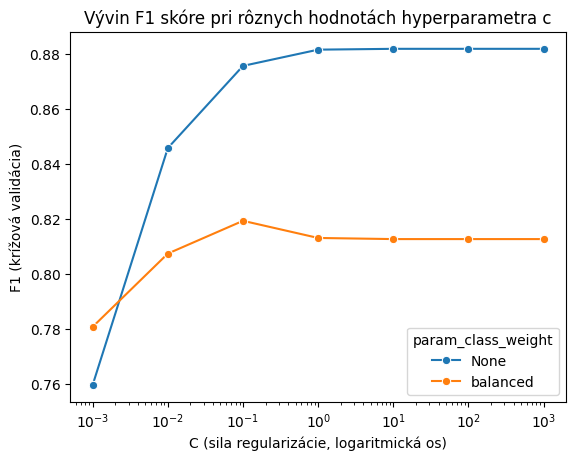

In [51]:
# výsledky všetkých vyskúšaných kombinácií hyperparametrov
results_lr = pd.DataFrame(gridsearch_lr.cv_results_)

# F1 pre každé C, zvlášť pre class_weight None a "balanced"
sns.lineplot(data=results_lr, x="param_C", y="mean_test_score",
             hue=results_lr["param_class_weight"].fillna("None"), marker="o")
plt.xscale("log")   # hodnoty C sú 0,01 až 100, preto logaritmická os
plt.xlabel("C (sila regularizácie, logaritmická os)")
plt.ylabel("F1 (krížová validácia)")
plt.title("Vývin F1 skóre pri rôznych hodnotách hyperparametra c")
plt.show()

Bez váhovania tried F1 rastie so zvyšujúcim sa C a od C = 1 sa ustáli na 0,882. Pri slabšej regularizácii sa model už nezlepšuje, ale ani nepretrénuje. Pri veľmi malom C (0,001) je regularizácia príliš silná a model je príliš jednoduchý (F1 0,76).

Najlepšia kombinácia je C = 10 bez váhovania tried.

## 3.2 K-najbližších susedov (KNN)
Model si zapamätá trénovacie dáta, pre nový bod nájde k najbližších
bodov (euklidovská vzdialenosť) a priradí triedu, ktorá medzi nimi prevláda.

Nerobí žiadny predpoklad o tvare hranice medzi triedami, takže dokáže zachytiť aj nelineárne vzťahy. Kvôli vzdialenostiam je nutné škálovanie.

Ladíme:
* `n_neighbors`: počet susedov (malé k = citlivé na šum, veľké k = príliš hladká hranica).
* `weights`: či majú bližší susedia väčší hlas.
* `metric`: spôsob merania vzdialenosti (`euclidean` = „vzdušná čiara“, `manhattan` = súčet rozdielov v jednotlivých premenných).

In [55]:
# mriežka hyperparametrov: počet susedov, váha hlasov susedov a spôsob merania vzdialenosti
params_knn = {"n_neighbors": list(range(5, 52, 2)),
              "weights": ["uniform", "distance"],
              "metric": ["euclidean", "manhattan"]}

gridsearch_knn = GridSearchCV(
    KNeighborsClassifier(),
    params_knn,
    scoring="f1")
gridsearch_knn.fit(X_train_scaled, y_train)

print(gridsearch_knn.best_params_, "| F1:", round(gridsearch_knn.best_score_, 3))
knn = gridsearch_knn.best_estimator_

{'metric': 'euclidean', 'n_neighbors': 21, 'weights': 'uniform'} | F1: 0.875


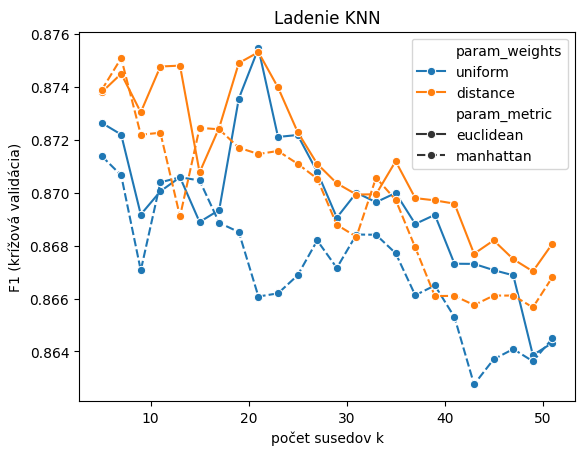

In [56]:
# výsledky všetkých vyskúšaných kombinácií hyperparametrov
results_knn = pd.DataFrame(gridsearch_knn.cv_results_)

# F1 podľa počtu susedov; farba = weights, plná/prerušovaná čiara = metric
sns.lineplot(data=results_knn, x="param_n_neighbors", y="mean_test_score",
             hue="param_weights", style="param_metric", marker="o")
plt.xlabel("počet susedov k")
plt.ylabel("F1 (krížová validácia)")
plt.title("Ladenie KNN")
plt.show()

Najvyššie F1 (0,875) dosiahol KNN s k = 21, euklidovskou vzdialenosťou a rovnakou váhou susedov. Do k ≈ 25 je výkon vysoký, pri väčšom počte susedov F1 klesá. Rozdiely medzi všetkými kombináciami sú malé (F1 0,863 – 0,876), takže na voľbe hyperparametrov pri KNN veľmi nezáleží.

## 3.3 Random Forest
Natrénuje veľa rozhodovacích stromov. Každý strom sa učí na náhodnej vzorke riadkov (bootstrap) a v každom uzle vyberá z náhodnej podmnožiny premenných. Výsledok je hlasovanie všetkých stromov.
Vďaka tomu je stabilnejší a menej náchylný na pretrénovanie ako jeden strom.

Prečo: nepotrebuje škálovanie, je odolný voči odľahlým hodnotám a vie zachytiť nelineárne vzťahy aj interakcie premenných. Navyše ukáže, ktoré premenné sú pre rozhodovanie najdôležitejšie.

Ladíme:
* `max_depth`: maximálna hĺbka stromu,
* `min_samples_leaf`: minimálny počet pozorovaní v liste (väčšie číslo = jednoduchšie stromy),
* `class_weight`: či zvýšiť váhu pulzarov.

In [ ]:
# mriežka hyperparametrov: hĺbka stromov, min. počet pozorovaní v liste, váha pulzarov
params_rf = {"max_depth": [None, 10],
             "min_samples_leaf": [1, 3],
             "class_weight": [None, "balanced"]}
# random_state=42 zabezpečí, že náhodný výber v lese dá pri každom spustení rovnaký výsledok
gridsearch_rf = GridSearchCV(RandomForestClassifier(random_state=42), params_rf, scoring="f1")
gridsearch_rf.fit(X_train_scaled, y_train)

print(gridsearch_rf.best_params_, "| F1:", round(gridsearch_rf.best_score_, 3))
forest = gridsearch_rf.best_estimator_

{'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1} | F1: 0.885


## 3.4 Výsledky ladenia
| Model | Najlepšie hyperparametre | F1 (krížová validácia) |
|---|---|---|
| Logistická regresia | C = 10, bez váhovania tried | 0,882 |
| KNN | k = 5, manhattanská vzdialenosť, bližší susedia majú väčšiu váhu | 0,874 |
| Random Forest | hĺbka stromov bez obmedzenia, min. 1 pozorovanie v liste, bez váhovania tried | 0,885 |

* `class_weight="balanced"` si nevybral ani jeden model. Vyššia váha pulzarov síce zvýši recall, no pridá viac falošných poplachov, takže F1 celkovo klesne.
* **Prečo to nejde výrazne lepšie:** Všetky tri modely, hoci fungujú na úplne odlišných princípoch, dosiahli takmer rovnaké F1 (okolo 0,88). Ak by bol problém v konkrétnom modeli, iný model by bol výrazne lepší. Hranica je preto daná samotnými dátami: časť pulzarov a šumu má takmer rovnaké hodnoty premenných (prekrytie kriviek v časti 1.4). Takýchto kandidátov nedokáže spoľahlivo rozlíšiť žiadny model, pretože informácia, ktorá by ich odlíšila, v dátach chýba.

# 4. Vyhodnotenie a porovnanie modelov na testovacích dátach
Až teraz prvýkrát použijeme testovacie dáta, ktoré žiaden model ani GridSearch predtým nevideli.

In [ ]:
# vyladené modely z časti 3
models = {"Logistická regresia": log_reg, "KNN": knn, "Random Forest": forest}

# pre každý model predikcia na testovacích dátach a výpočet metrík
rows = []
for name, model in models.items():
    pred = model.predict(X_test_scaled)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

# tabuľka výsledkov zoradená podľa F1
results = pd.DataFrame(rows).set_index("Model").round(3)
print("Accuracy modelu, ktorý vždy tipne šum:", round(1 - y_test.mean(), 3))
results.sort_values("F1", ascending=False)

Accuracy modelu, ktorý vždy tipne šum: 0.908


,Accuracy,Precision,Recall,F1
Model,,,,
Random Forest,0.980,0.916,0.863,0.889
Logistická regresia,0.980,0.933,0.848,0.888
KNN,0.977,0.902,0.841,0.871


Všetky tri modely dosahujú accuracy 98 %, oproti 90,8 % pri modeli, ktorý vždy tipne šum. Accuracy však modely takmer nerozlíši, preto sa pozeráme na ďalšie metriky.
* **Random Forest** (F1 = 0,889) a **logistická regresia** (F1 = 0,888) sú prakticky rovnako dobré. Rozdiel 0,001 predstavuje jedného kandidáta.
* **Logistická regresia** má najvyššiu precision (0,933), teda najmenej falošných poplachov.
* **Random Forest** má najvyšší recall (0,863), teda nájde najviac pulzarov.
* **KNN** je o niečo slabší (F1 = 0,871) v precision aj v recall.

## 4.1 Matice zámen
Riadky = skutočnosť, stĺpce = predikcia. Vpravo hore sú **falošné poplachy** (šum označený ako pulzar),
vľavo dole **prehliadnuté pulzary**.

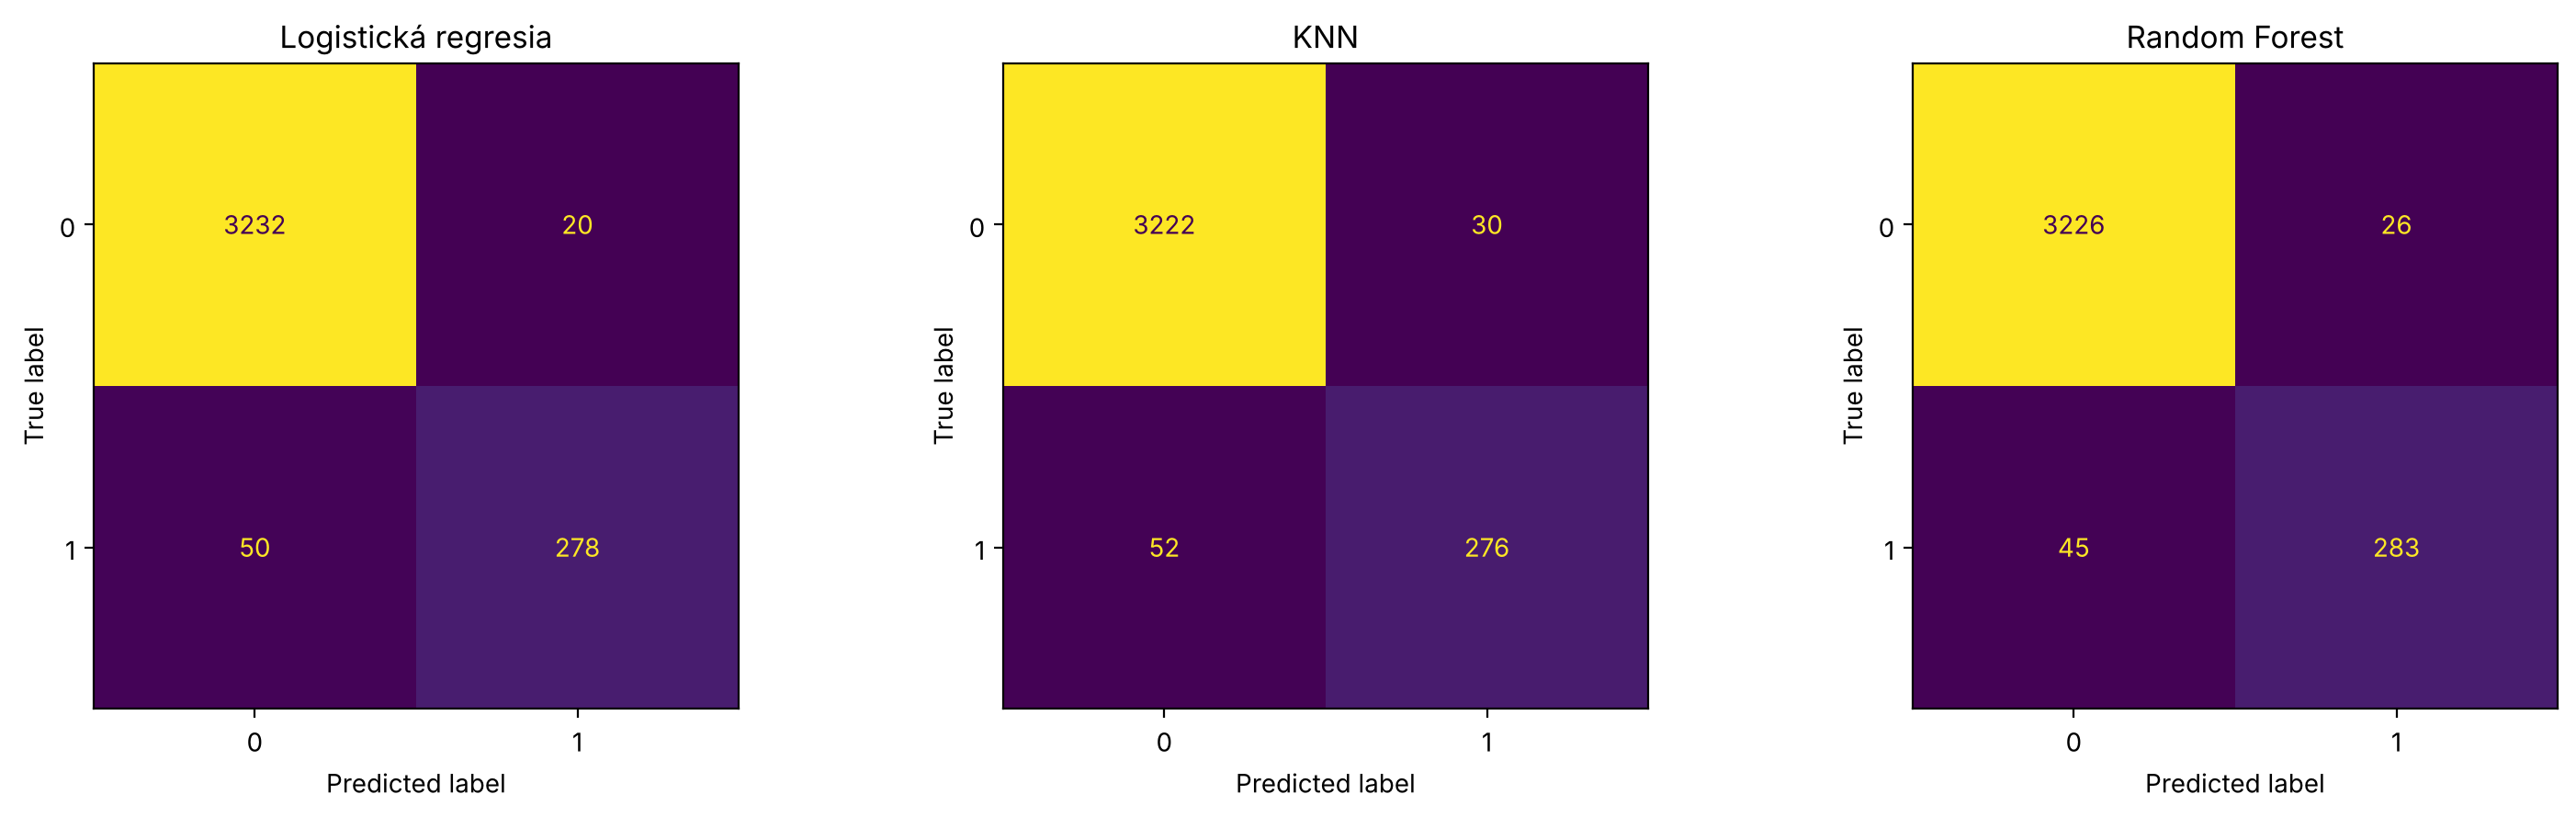

In [ ]:
# matica zámen pre každý model vedľa seba
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test_scaled, y_test,
                                          ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Random Forest z 328 pulzarov v testovacích dátach správne našiel **283** a prehliadol 45. Spomedzi 3 252 kandidátov so šumom označil ako pulzar 26. Logistická regresia vyvolala najmenej falošných poplachov (20), no prehliadla 50 pulzarov. KNN prehliadol 52 pulzarov a vyvolal 30 falošných poplachov.

## 4.2 ROC krivky
ROC krivka ukazuje, ako sa mení podiel nájdených pulzarov (true positive rate) a falošných poplachov
(false positive rate) pri rôznych rozhodovacích prahoch. **AUC** (plocha pod krivkou) = pravdepodobnosť,
že model priradí náhodnému pulzaru vyššie skóre ako náhodnému šumu. 1 = dokonalý model, 0,5 = hádanie.

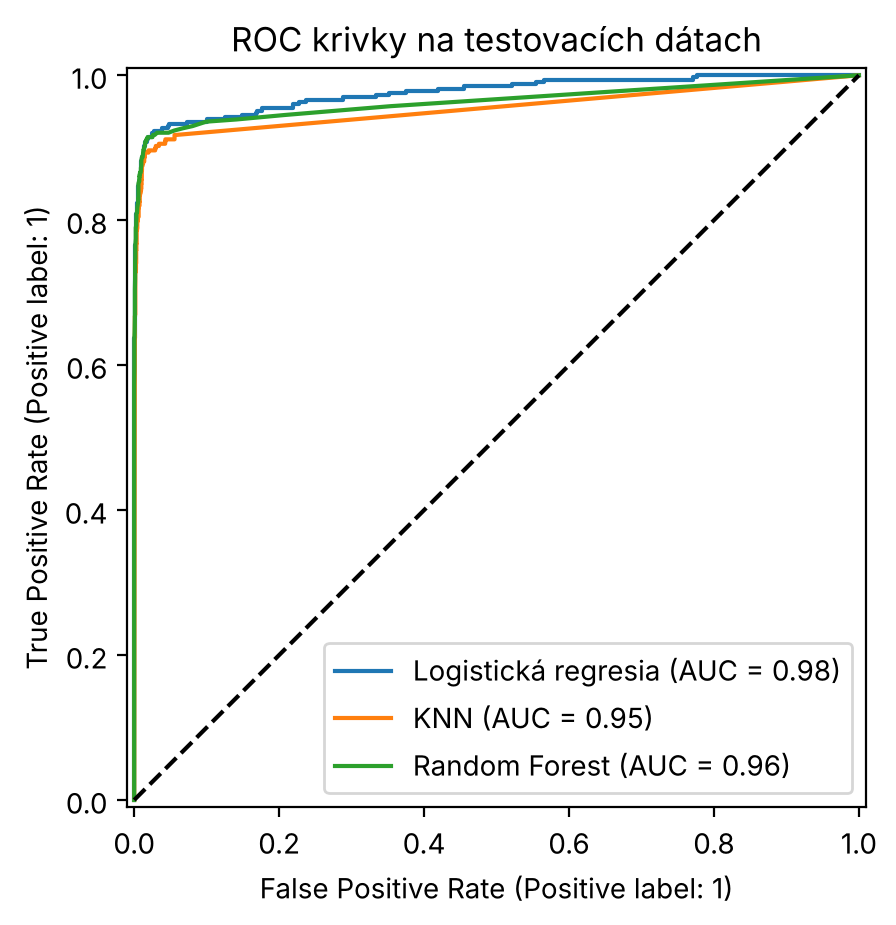

In [ ]:
# ROC krivky všetkých modelov do jedného grafu
ax = plt.gca()
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test_scaled, y_test,
                                   name=name, ax=ax)
# prerušovaná diagonála = model, ktorý len háda
plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC krivky na testovacích dátach")
plt.show()

Všetky modely majú **AUC 0,95 – 0,98**, teda veľmi dobrú schopnosť odlíšiť pulzar od šumu. Najvyššiu AUC má logistická regresia (0,976), nasleduje Random Forest (0,964) a KNN (0,954). Pri nízkej miere falošných poplachov (oblasť, ktorá nás reálne zaujíma) sú krivky takmer totožné. To, že najjednoduchší model má najvyššiu AUC, potvrdzuje, že po transformácii premenných tu lineárna hranica stačí.

## 4.3 Najlepší model

In [ ]:
# model s najvyšším F1 a jeho podrobné metriky pre obe triedy
best_name = results["F1"].idxmax()
print("Najlepší model podľa F1:", best_name, "\n")
best_pred = models[best_name].predict(X_test_scaled)
print(classification_report(y_test, best_pred,
                            target_names=["šum", "pulzar"]))

Najlepší model podľa F1: Random Forest 

              precision    recall  f1-score   support

         šum       0.99      0.99      0.99      3252
      pulzar       0.92      0.86      0.89       328

    accuracy                           0.98      3580
   macro avg       0.95      0.93      0.94      3580
weighted avg       0.98      0.98      0.98      3580



Najvyššie F1 na testovacích dátach dosiahol **Random Forest**: nájde 86 % pulzarov a z kandidátov, ktoré označí ako pulzar, je 92 % skutočných.

**Logistická regresia** je však len o 0,001 F1 horšia, má najvyššiu precision aj AUC a dá sa zapísať jedným vzorcom. Ak by sme chceli **jednoduchý, rýchly a vysvetliteľný** model, zvolíme ju. Či je rozdiel medzi modelmi skutočný, overíme v časti 4.5.

## 4.4 Ktoré premenné rozhodujú?
Random Forest meria dôležitosť premennej podľa toho, o koľko v priemere zníži nečistotu (Gini) v uzloch,
kde sa podľa nej delí.

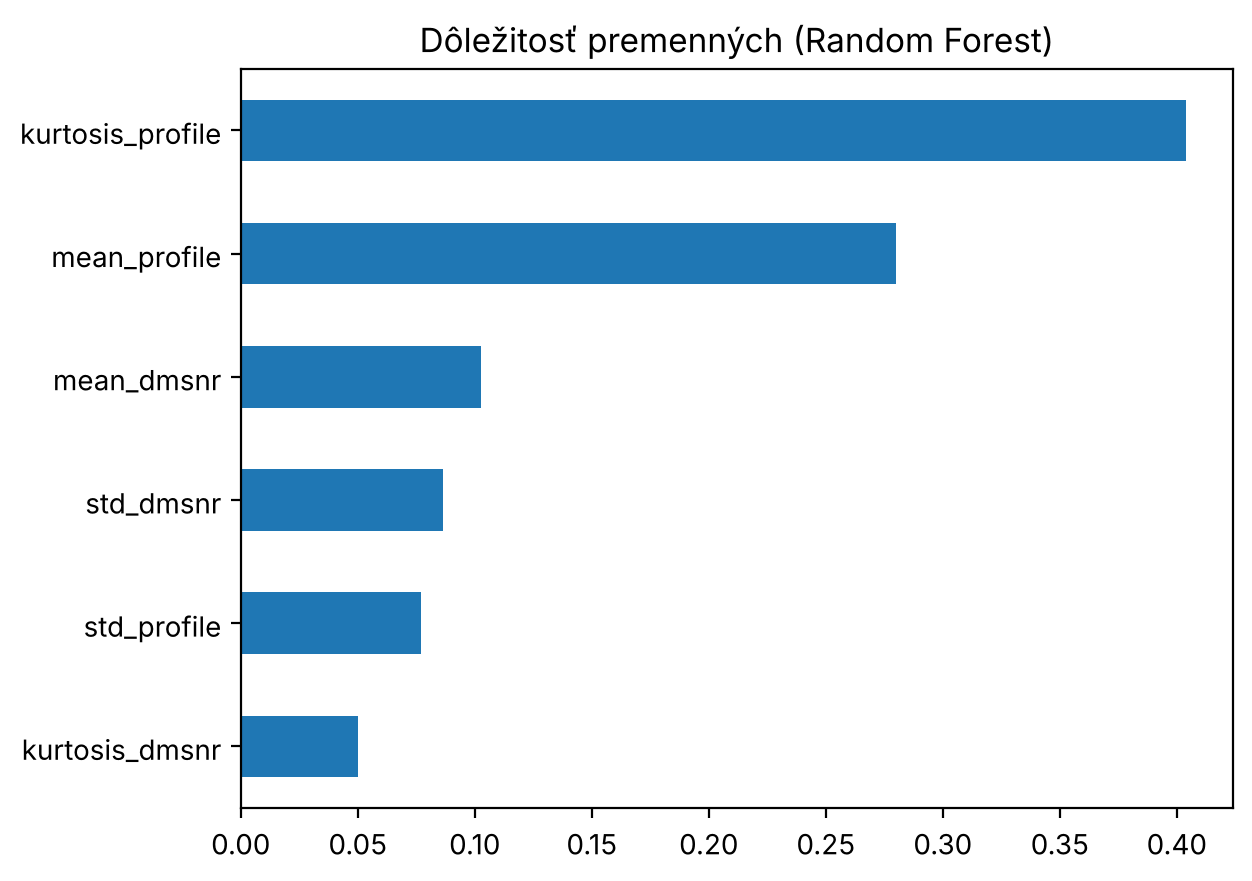

In [ ]:
# dôležitosť premenných podľa Random Forestu, zoradená od najmenšej
importance = pd.Series(forest.feature_importances_, index=X_train.columns)
importance = importance.sort_values()
importance.plot.barh(title="Dôležitosť premenných (Random Forest)")
plt.show()

Najdôležitejšia je **špicatosť integrovaného profilu** (`kurtosis_profile`, 40 %) a **priemer integrovaného profilu** (28 %). Spolu tvoria takmer 70 % rozhodovania. Má to aj fyzikálny zmysel: skutočný pulzar vytvára **krátky, ostrý pulz**, ktorý sa opakuje pri každej otáčke, kým šum je rozmazaný a plochý.

## 4.5 Sú rozdiely medzi modelmi skutočné?
V testovacej vzorke je iba 328 pulzarov, takže rozdiel v F1 o 0,01 predstavuje len niekoľko kandidátov a môže byť náhoda. Modely preto porovnáme ešte raz pomocou **opakovanej krížovej validácie** na trénovacích dátach: dáta sa 5-krát náhodne rozdelia na 5 foldov, takže každý model sa natrénuje a ohodnotí **25-krát**. Namiesto jedného čísla tak dostaneme rozdelenie F1 skóre. Používame už vyladené modely z časti 3.

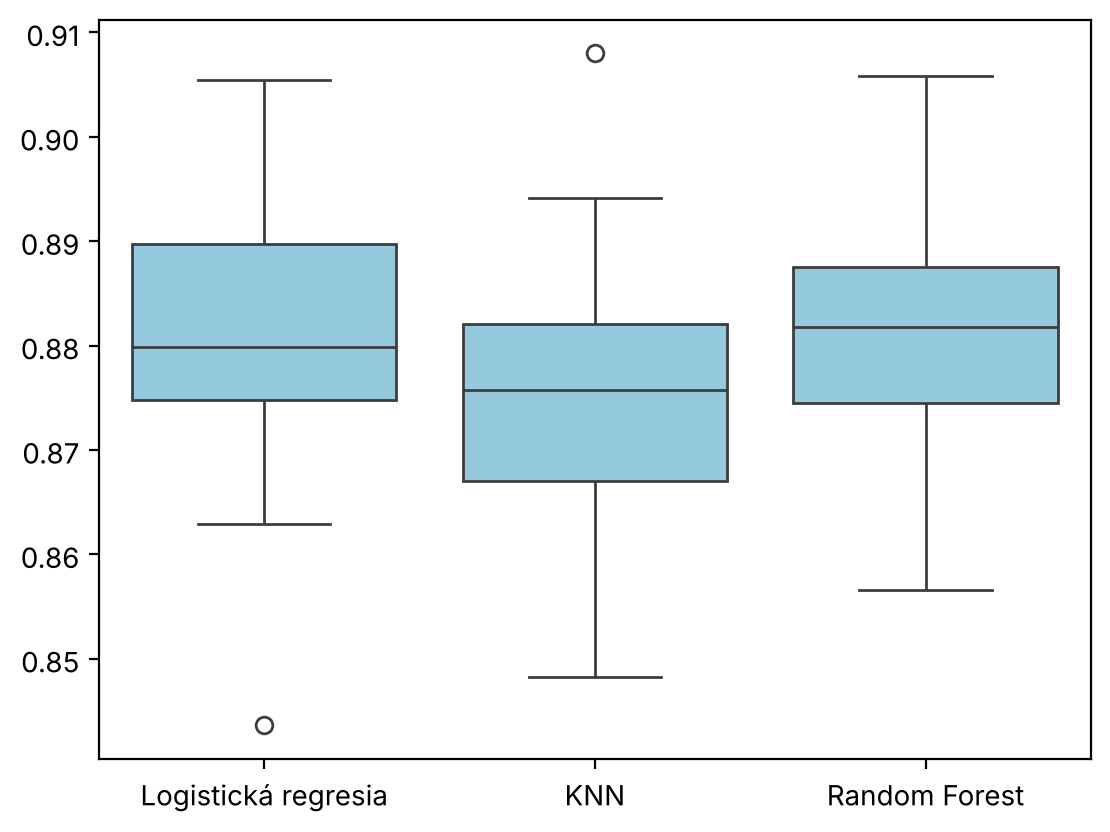

,mean,std,min,max
Logistická regresia,0.882,0.013,0.844,0.905
KNN,0.874,0.014,0.848,0.908
Random Forest,0.881,0.011,0.857,0.906


In [ ]:
# 5-násobná krížová validácia zopakovaná 5-krát s iným náhodným rozdelením = 25 F1 skóre pre každý model
cv = RepeatedStratifiedKFold(n_repeats=5, random_state=42)
cv_scores = pd.DataFrame({name: cross_val_score(model, X_train_scaled, y_train, scoring="f1", cv=cv)
                          for name, model in models.items()})

# rozdelenie F1 skóre každého modelu
sns.boxplot(data=cv_scores, color="skyblue")
plt.show()
cv_scores.agg(["mean", "std", "min", "max"]).T.round(3)

* Priemerné F1 má **logistická regresia 0,882, Random Forest 0,881 a KNN 0,874**, no jednotlivé behy kolíšu v rozmedzí 0,84 – 0,91. **Krabice všetkých modelov sa prekrývajú**: rozdiely medzi modelmi sú menšie ako kolísanie medzi jednotlivými rozdeleniami dát.
* Logistická regresia a Random Forest sú prakticky rovnocenné, KNN je mierne slabší.
* Random Forest je najstabilnejší (smerodajná odchýlka 0,011), logistická regresia a KNN kolíšu o niečo viac (0,013 – 0,014).
* **Záver:** pri rovnakom výkone dávame prednosť **jednoduchšiemu a vysvetliteľnejšiemu modelu**, teda logistickej regresii. Ak by sme chceli o niečo vyšší recall, zvolíme Random Forest.

## 4.6 Bonus: našli by sme pulzary aj bez značiek? (K-means)
Doteraz sme modely učili na dátach, kde človek ku každému kandidátovi určil, či je pulzar. Čo keby sme tieto značky nemali? Vyskúšame **zhlukovanie (clustering)** metódou **K-means**, ktorá patrí medzi metódy **učenia bez učiteľa**: `target_pulsar` vôbec nepoužíva. Značky použijeme až na kontrolu výsledku.

**Ako K-means funguje:**
1. náhodne zvolí *k* stredov (centroidov),
2. každého kandidáta priradí k najbližšiemu stredu,
3. stredy presunie do priemeru priradených bodov,
4. kroky 2 a 3 opakuje, kým sa priradenie nemení.

Výsledkom je *k* skupín (klastrov) podobných kandidátov. K-means pracuje so vzdialenosťami, preto dáta štandardizujeme. Na rozdiel od KNN nepozná žiadne triedy, iba hľadá skupiny podobných bodov.

### Koľko klastrov zvoliť?
Počet klastrov *k* musíme určiť sami. Pomôžu nám dve miery:
* **Inercia** (metóda lakťa): súčet štvorcov vzdialeností bodov od stredu ich klastra. S rastúcim *k* vždy klesá, hľadáme „lakeť“, za ktorým už klesá iba pomaly.
* **Silhouette skóre**: pre každý bod porovná, ako blízko je k bodom vo svojom klastri a ako blízko k najbližšiemu inému klastru. Nadobúda hodnoty od −1 do 1, **čím vyššie, tým lepšie sú klastre od seba oddelené**.

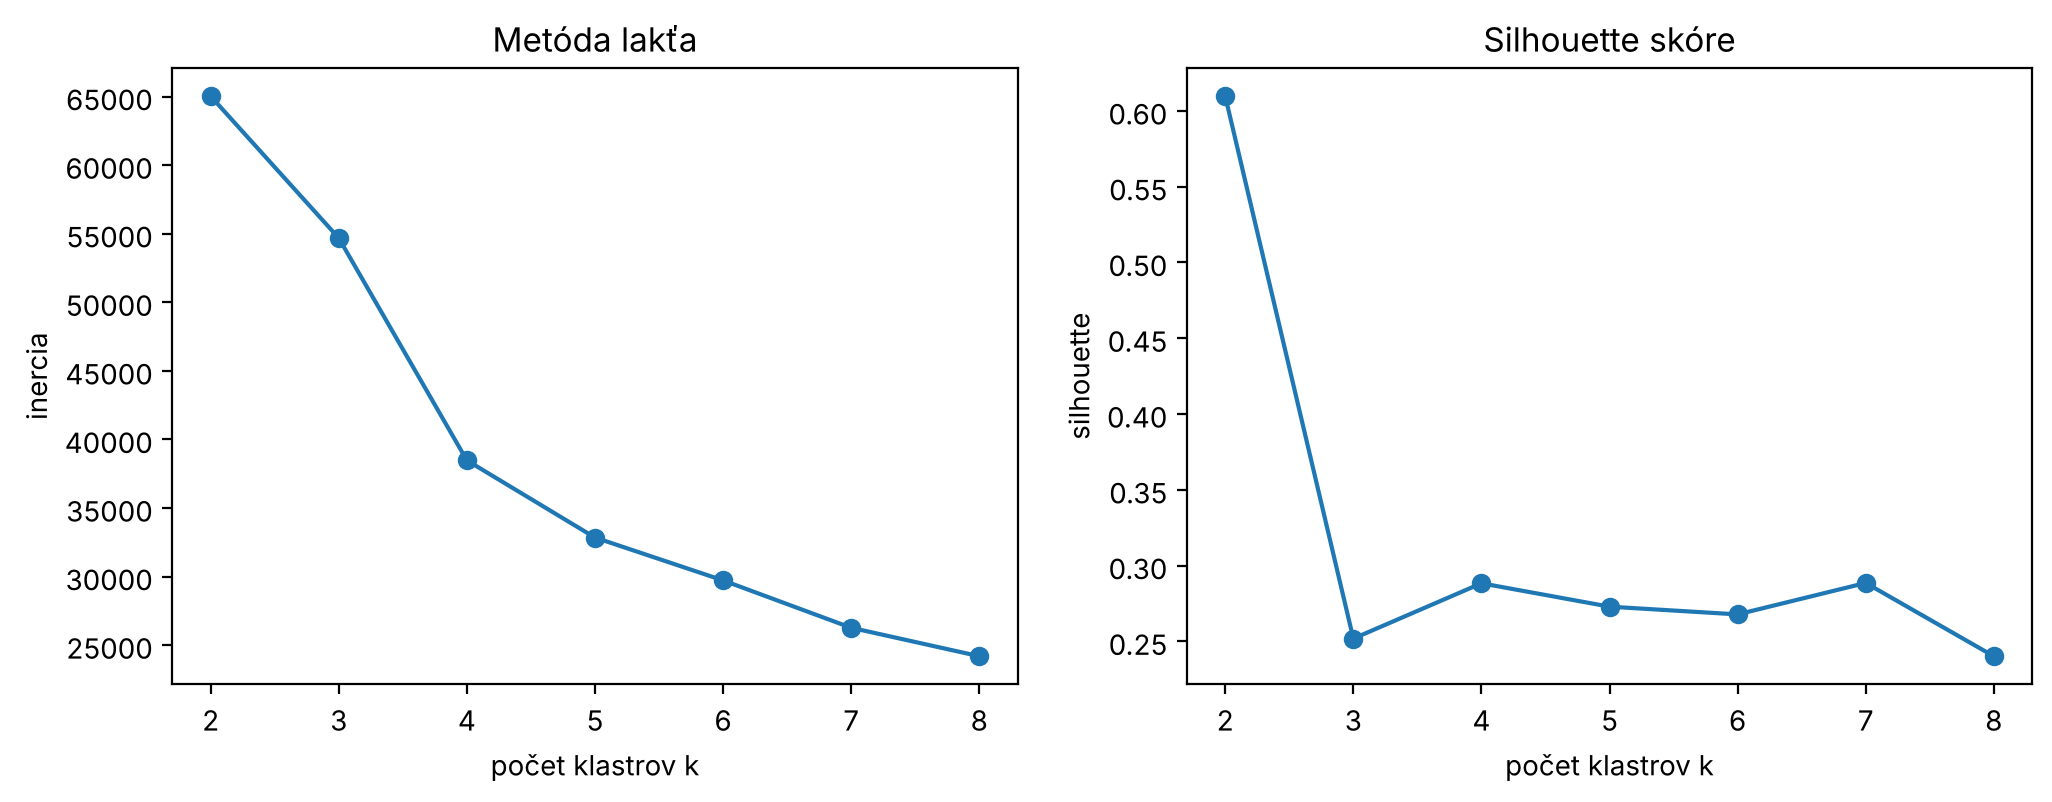

In [ ]:
# K-means pracuje so vzdialenosťami, preto dáta štandardizujeme
X_all = StandardScaler().fit_transform(df[X_train.columns])

# pre k = 2 až 8 vypočítame inerciu a silhouette skóre
k_values = range(2, 9)
inertia, silhouette = [], []
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42).fit(X_all)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X_all, kmeans.labels_))

# oba grafy vedľa seba
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertia, marker="o")
axes[0].set(title="Metóda lakťa", xlabel="počet klastrov k", ylabel="inercia")
axes[1].plot(k_values, silhouette, marker="o")
axes[1].set(title="Silhouette skóre", xlabel="počet klastrov k", ylabel="silhouette")
plt.show()

* **Inercia** výrazne klesá až po k = 4, potom už iba pomaly. „Lakeť“ je teda pri **k = 4**.
* **Silhouette skóre je pri k = 2 výrazne najvyššie (0,61)**, pri ostatných hodnotách je len 0,24 – 0,29. Podľa neho sa dáta najprirodzenejšie delia na **dve skupiny**, čo je presne počet našich tried.
* Miery sa nezhodujú, preto vyskúšame obe možnosti. Začneme s **k = 2** a k = 4 vyskúšame na konci.

In [ ]:
# rozdelíme kandidátov do 2 klastrov bez použitia značiek
clusters = KMeans(n_clusters=2, random_state=42).fit_predict(X_all)
# až teraz porovnáme klastre so skutočnými triedami
pd.crosstab(clusters, df["target_pulsar"])

target_pulsar,0,1
row_0,,
0,15375,351
1,884,1288


Klaster 1 zachytil **1 288 z 1 639 pulzarov (79 %)**, hoci model nikdy nevidel, čo je pulzar. Obsahuje však aj 884 kandidátov so šumom, takže pulzary tvoria iba **59 %** jeho členov. Klaster 0 je takmer čistý šum (98 %).

Porovnajme klastre so skutočnými triedami v grafe dvoch najdôležitejších premenných:

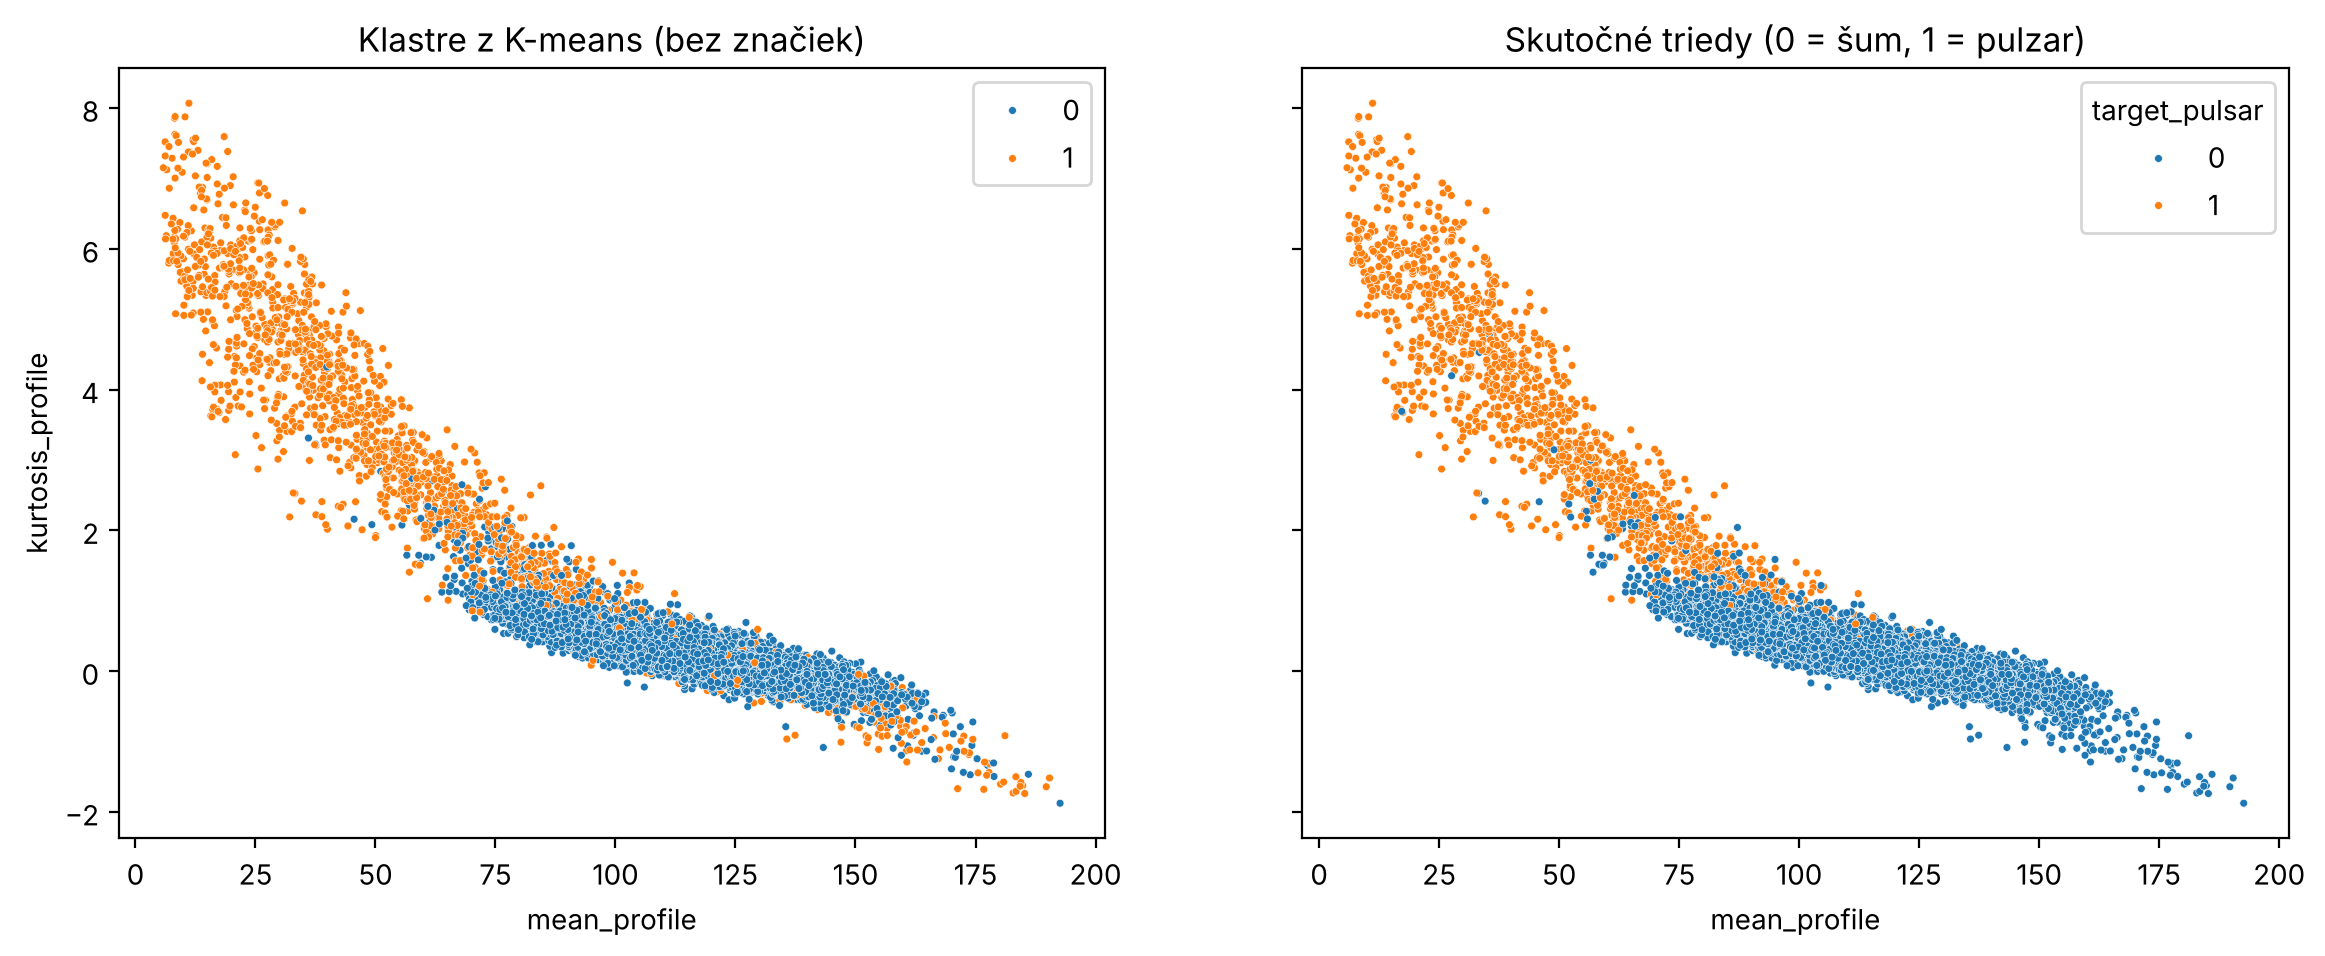

In [ ]:
# vľavo farby podľa klastrov z K-means, vpravo podľa skutočných tried
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.scatterplot(data=df, x="mean_profile", y="kurtosis_profile", hue=clusters, s=8, ax=axes[0])
axes[0].set_title("Klastre z K-means (bez značiek)")
sns.scatterplot(data=df, x="mean_profile", y="kurtosis_profile", hue="target_pulsar", s=8, ax=axes[1])
axes[1].set_title("Skutočné triedy (0 = šum, 1 = pulzar)")
plt.show()

Oba grafy vyzerajú veľmi podobne: K-means oddelil skupinu s nízkym `mean_profile` a vysokou `kurtosis_profile`, kde ležia pulzary. Rozdiely sú na dvoch miestach:
* v **prechodovej oblasti** (`mean_profile` približne 70 – 100), kde sa šum a pulzary miešajú,
* **vpravo dole** (`mean_profile` nad ~150): tieto kandidáty sú šum, no K-means ich zaradil k pulzarom. V tomto grafe vyzerajú ako šum, podobajú sa však na pulzary v premenných DM-SNR krivky, ktoré tu nevidno.

K-means kreslí hranice „podľa tvaru dát“ vo všetkých 6 premenných naraz, nie podľa skutočných tried, a preto do klastra 1 zaradil aj časť šumu.

Ako vyzerá „typický“ člen každého klastra? Porovnáme priemery premenných:

In [ ]:
# priemerné hodnoty premenných v každom klastri; priemer target_pulsar = podiel pulzarov v klastri
df.groupby(clusters)[list(X_train.columns) + ["target_pulsar"]].mean().round(2)

,mean_profile,std_profile,kurtosis_profile,mean_dmsnr,std_dmsnr,kurtosis_dmsnr,target_pulsar
0,115.81,47.03,0.23,3.82,20.34,9.31,0.02
1,76.86,43.10,2.27,76.28,69.69,0.99,0.59


Klaster 1 má všetky znaky pulzarov, ktoré sme videli v EDA: nižší `mean_profile`, vyššiu `kurtosis_profile`, vysoký `mean_dmsnr` a `std_dmsnr` a nízku `kurtosis_dmsnr`. K-means teda bez akejkoľvek nápovedy objavil tie isté rozdiely, ktoré sme v časti 1.4 hľadali pomocou značiek.

### Čo ak zvolíme viac klastrov?
Metóda lakťa naznačila k = 4. Pri viacerých klastroch môže K-means oddeliť jemnejšie skupiny:

In [ ]:
# 4 klastre a ich porovnanie so skutočnými triedami
clusters_4 = KMeans(n_clusters=4, random_state=42).fit_predict(X_all)
pd.crosstab(clusters_4, df["target_pulsar"])

target_pulsar,0,1
row_0,,
0,6075,327
1,1034,173
2,9127,90
3,23,1049


Výsledok je prekvapivý: **klaster 3 obsahuje 1 072 kandidátov a 98 % z nich (1 049) sú pulzary**. To sú **„jasné“ pulzary**, ktoré sa od šumu líšia natoľko, že ich K-means spoľahlivo oddelí aj bez značiek. Je to 64 % všetkých pulzarov. Zvyšných ~590 pulzarov je rozptýlených v klastroch so šumom, sú to tie ťažké prípady z prechodovej oblasti.

**Zhrnutie:**

| Metóda | Nájdené pulzary (recall) | Podiel pulzarov medzi označenými (precision) |
|---|---|---|
| K-means, k = 2 (klaster 1) | 79 % | 59 % |
| K-means, k = 4 (klaster 3) | 64 % | 98 % |
| Logistická regresia (s učiteľom) | 85 % | 93 % |

Pulzary v dátach tvoria vlastnú skupinu, ktorú K-means nájde aj bez značiek. „Jasné“ pulzary dokáže oddeliť takmer bezchybne. Značky od ľudí sú však potrebné na **ťažké prípady v prechodovej oblasti**: model s učiteľom nájde viac pulzarov a zároveň s oveľa menším počtom falošných poplachov.

## 4.7 Koľko kandidátov musí astronóm skontrolovať?
Model povie „pulzar“, keď je pravdepodobnosť vyššia ako **0,5**. Tento prah však nie je povinný. Keď ho znížime, model nájde viac pulzarov, ale označí aj viac šumu, ktorý musí astronóm ručne vylúčiť.

Položíme si praktickú otázku: **ak chceme nájsť 90 %, 95 % alebo 99 % všetkých pulzarov, koľko kandidátov musí astronóm skontrolovať?** Použijeme vybraný model, logistickú regresiu.

**Precision-recall krivka** ukazuje, ako sa pri posúvaní prahu mení recall (podiel nájdených pulzarov) a precision (podiel pulzarov medzi označenými). Body na krivke označujú naše tri ciele.

Nájsť 90% pulzarov: prah 0.228, skontrolovať 342 kandidátov, z toho pulzary 87%
Nájsť 95% pulzarov: prah 0.019, skontrolovať 865 kandidátov, z toho pulzary 36%
Nájsť 99% pulzarov: prah 0.002, skontrolovať 2126 kandidátov, z toho pulzary 15%
Pri prahu 0,5: 298 kandidátov


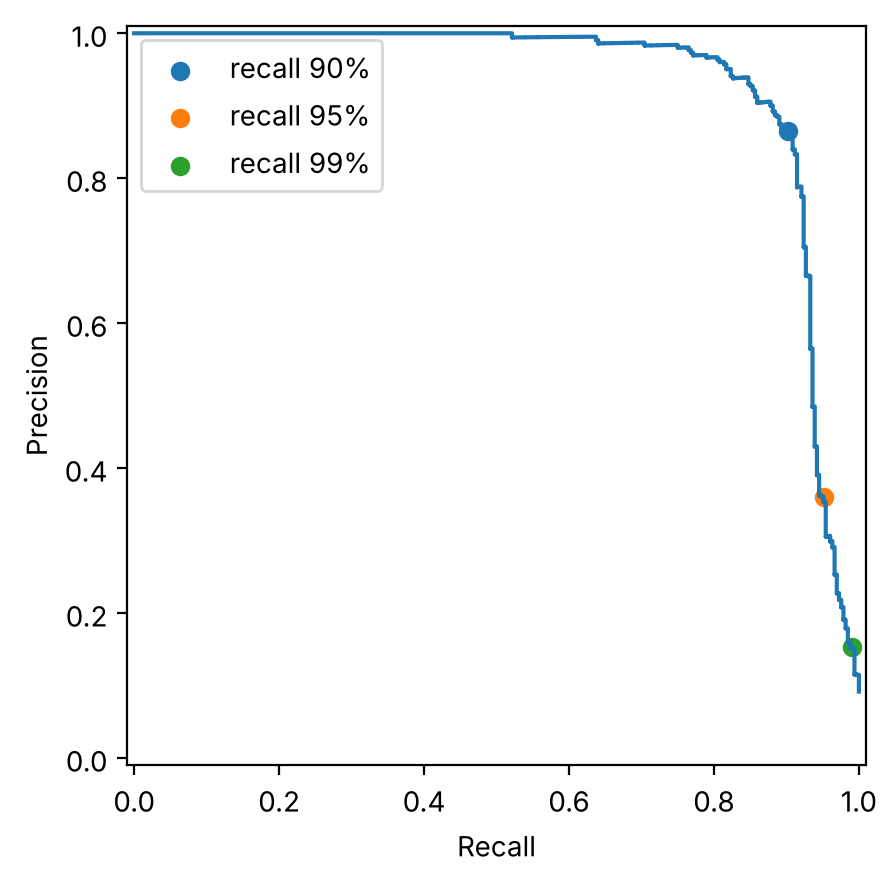

In [ ]:
# pravdepodobnosť, že kandidát je pulzar (podľa logistickej regresie)
proba = log_reg.predict_proba(X_test_scaled)[:, 1]
# precision a recall pre všetky možné prahy
precision, recall, thresholds = precision_recall_curve(y_test, proba)
PrecisionRecallDisplay(precision=precision, recall=recall).plot()

for target in [0.90, 0.95, 0.99]:
    # najvyšší prah, pri ktorom model ešte nájde aspoň požadovaný podiel pulzarov
    i = (recall >= target).nonzero()[0][-1]
    plt.scatter(recall[i], precision[i], label=f"recall {target:.0%}")
    print(f"Nájsť {target:.0%} pulzarov: prah {thresholds[i]:.3f}, "
          f"skontrolovať {(proba >= thresholds[i]).sum()} kandidátov, z toho pulzary {precision[i]:.0%}")

# pre porovnanie: počet označených kandidátov pri predvolenom prahu 0,5
print("Pri prahu 0,5:", (proba >= 0.5).sum(), "kandidátov")
plt.legend()
plt.show()

| Cieľ (recall) | Prah | Kandidátov na kontrolu (z 3 580) | Z toho pulzary |
|---|---|---|---|
| prah 0,5 (predvolený) | 0,500 | 298 | 93 % (nájde 85 % pulzarov) |
| 90 % | 0,228 | 342 | 87 % |
| 95 % | 0,019 | 865 | 36 % |
| 99 % | 0,002 | 2 126 | 15 % |

* Zvýšiť recall z 85 % na **90 %** je takmer zadarmo: stačí skontrolovať o 44 kandidátov viac a stále je 87 % z nich pulzarov.
* Pre **95 %** treba skontrolovať už **2,5-krát viac** kandidátov a takmer dve tretiny z nich sú šum.
* Pre **99 %** by musel astronóm prejsť **59 % všetkých kandidátov**. Posledné percentá pulzarov sú tie, ktoré vyzerajú ako šum, a nájsť ich je veľmi drahé.
* Rozumný kompromis je preto prah okolo **0,2 – 0,25**, ktorý nájde 90 % pulzarov za cenu len o málo väčšej ručnej práce. Voľba prahu nie je otázka modelu, ale toho, **koľko času majú astronómovia** a koľko pulzarov sú ochotní prehliadnuť.

*Poznámka: prahy sme pre ilustráciu určili na testovacích dátach. V praxi by sa prah vyberal na samostatnej validačnej časti dát.*

# 5. Záver

* Na datasete HTRU2 (17 898 kandidátov, 9 % pulzarov) sme natrénovali a porovnali **3 klasifikačné modely**: logistickú regresiu, KNN a Random Forest. Hyperparametre sme ladili cez `GridSearchCV` s 5-násobnou krížovou validáciou podľa F1 skóre.
* **Príprava dát:** dáta sú čisté (bez chýbajúcich hodnôt a duplicít). Odľahlé hodnoty sme ponechali, lebo prevažne patria pulzarom. Dve premenné (`skewness_profile`, `skewness_dmsnr`) sme vyradili ako nadbytočné, lebo korelovali s inými premennými na úrovni r > 0,9 a ich odstránenie výkon nezhoršilo. Zošikmené premenné sme upravili Yeo-Johnsonovou transformáciou a štandardizovali.
* **Výsledky:** všetky modely dosiahli accuracy ~98 %, F1 0,87 – 0,89 a AUC 0,95 – 0,98. Najlepšie F1 na testovacích dátach má **Random Forest (0,889)**, tesne za ním **logistická regresia (0,888)** s najvyššou precision aj AUC. Opakovaná krížová validácia ukázala, že **rozdiely medzi modelmi sú v rámci náhodného kolísania**, preto vyberáme najjednoduchšiu logistickú regresiu.
* **Strop výkonu:** všetky modely skončili okolo F1 0,88, pretože časť pulzarov a šumu má takmer rovnaké hodnoty premenných a v dátach chýba informácia, ktorá by ich odlíšila.
* **Rozhodovací prah:** posunutím prahu z 0,5 na ~0,23 nájde model 90 % pulzarov a astronóm musí skontrolovať len o 44 kandidátov viac. Pre 99 % pulzarov by už musel skontrolovať 59 % všetkých kandidátov.
* **Bez značiek:** K-means (silhouette skóre jasne odporučilo 2 klastre) našiel bez akejkoľvek informácie o triedach 79 % pulzarov, no s veľa falošnými poplachmi. Pri 4 klastroch oddelil skupinu „jasných“ pulzarov s 98 % presnosťou. Pulzary teda v dátach tvoria vlastnú skupinu, ale na ťažké prípady sú potrebné značky od ľudí.
* **Hlavné zistenia:**
  1. Pri nevyvážených triedach je accuracy zavádzajúca. Model, ktorý nenájde ani jeden pulzar, má 90,8 %.
  2. Po vhodnej transformácii premenných je jednoduchá logistická regresia rovnako dobrá ako Random Forest.
  3. Rozhodujúca je špicatosť a priemer integrovaného profilu: pulzar má ostrý, pravidelný pulz.